<a href="https://colab.research.google.com/github/VictorManuelOrt/Biometric/blob/main/RBFBIOM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CODIGO

Configuración: xor
Datos: 640 muestras, 4 clases
Entrenamiento: 480, Prueba: 160
Distribución clases: {np.int64(0): np.int64(122), np.int64(1): np.int64(123), np.int64(2): np.int64(121), np.int64(3): np.int64(114)}


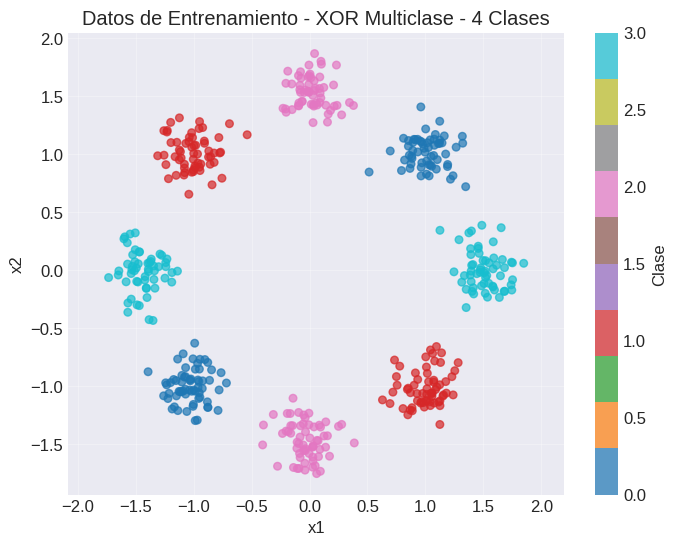

In [ ]:
# =============================================================================
# METRIC LEARNING CON RBF - MÚLTIPLES CLASES
# C
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# =============================================================================
# 1. GENERAR DATOS - MÚLTIPLES OPCIONES
# =============================================================================

np.random.seed(42)

def generar_circulos_concéntricos(n_por_clase=80, n_clases=4, ruido=0.1):
    """Genera círculos concéntricos con múltiples clases"""
    X = []
    y = []

    radios = np.linspace(0.5, 2.5, n_clases)

    for clase in range(n_clases):
        for _ in range(n_por_clase):
            angulo = np.random.uniform(0, 2*np.pi)
            radio = radios[clase] + np.random.randn() * ruido
            x = radio * np.cos(angulo)
            y_ = radio * np.sin(angulo)
            X.append([x, y_])
            y.append(clase)

    return np.array(X), np.array(y)

def generar_xor_multiclase(n_por_cluster=80):
    """Genera patrón XOR con 4 clases en las esquinas"""
    X = []
    y = []

    # Esquinas con clases diferentes
    esquinas = [
        (-1, -1, 0),  # Clase 0
        (1, 1, 0),    # Clase 0
        (-1, 1, 1),   # Clase 1
        (1, -1, 1),   # Clase 1
        (0, -1.5, 2), # Clase 2 (puntos extra)
        (0, 1.5, 2),  # Clase 2
        (-1.5, 0, 3), # Clase 3
        (1.5, 0, 3)   # Clase 3
    ]

    for cx, cy, cls in esquinas:
        for _ in range(n_por_cluster):
            x = cx + np.random.randn() * 0.15
            y_ = cy + np.random.randn() * 0.15
            X.append([x, y_])
            y.append(cls)

    return np.array(X), np.array(y)

def generar_espiral_multiclase(n_por_clase=100, n_clases=3, ruido=0.1):
    """Genera espirales con múltiples clases"""
    X = []
    y = []

    for clase in range(n_clases):
        for _ in range(n_por_clase):
            t = np.random.uniform(0, 4*np.pi)
            radio = 0.5 + t / (2*np.pi)
            angulo = t + clase * 2*np.pi / n_clases
            x = radio * np.cos(angulo) + np.random.randn() * ruido
            y_ = radio * np.sin(angulo) + np.random.randn() * ruido
            X.append([x, y_])
            y.append(clase)

    return np.array(X), np.array(y)

# =============================================================================
# 2. SELECCIONAR CONFIGURACIÓN
# =============================================================================

# Opciones: 'circulos', 'xor', 'espiral'
config = 'xor'  # CAMBIA AQUÍ PARA PROBAR OTRAS CONFIGURACIONES

if config == 'circulos':
    X, y = generar_circulos_concéntricos(n_por_clase=100, n_clases=4, ruido=0.1)
    titulo = "Círculos Concéntricos - 4 Clases"
elif config == 'xor':
    X, y = generar_xor_multiclase(n_por_cluster=80)
    titulo = "XOR Multiclase - 4 Clases"
else:  # espiral
    X, y = generar_espiral_multiclase(n_por_clase=100, n_clases=3, ruido=0.15)
    titulo = "Espirales - 3 Clases"

# Dividir en entrenamiento y prueba
indices = np.random.permutation(len(X))
split = int(0.75 * len(X))
X_train = X[indices[:split]]
y_train = y[indices[:split]]
X_test = X[indices[split:]]
y_test = y[indices[split:]]

n_clases = len(np.unique(y))
print(f"Configuración: {config}")
print(f"Datos: {len(X)} muestras, {n_clases} clases")
print(f"Entrenamiento: {len(X_train)}, Prueba: {len(X_test)}")
print(f"Distribución clases: {dict(zip(*np.unique(y_train, return_counts=True)))}")

# =============================================================================
# 3. VISUALIZAR DATOS ORIGINALES
# =============================================================================

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_train[:,0], X_train[:,1], c=y_train, cmap='tab10', s=30, alpha=0.7)
plt.colorbar(scatter, label='Clase')
plt.title(f'Datos de Entrenamiento - {titulo}')
plt.xlabel('x1')
plt.ylabel('x2')
plt.grid(True, alpha=0.3)
plt.axis('equal')
plt.show()

# =============================================================================
# 4. PARÁMETROS DEL MODELO
# =============================================================================

K = 30          # Número de funciones RBF (más para más clases)
d = 2           # Dimensión del embedding (2D para visualizar)
alpha = 0.5     # Margen Triplet Loss
lr = 0.03       # Tasa de aprendizaje
epochs = 150    # Iteraciones

# =============================================================================
# 5. INICIALIZAR PARÁMETROS
# =============================================================================

# Centroides: K-means
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
kmeans.fit(X_train)
mu = kmeans.cluster_centers_.copy()  # (K, 2)

# Anchos: basados en distancia promedio
distancias = []
for i in range(K):
    for j in range(i+1, K):
        distancias.append(np.linalg.norm(mu[i] - mu[j]))
sigma = np.mean(distancias) / 2.0 if distancias else 0.5
gamma = np.ones(K) / (2.0 * sigma**2)
gamma = np.clip(gamma, 0.1, 5.0)  # (K,)

# Pesos y sesgo
W = np.random.randn(d, K) * 0.01   # (2, K)
b = np.zeros(d)                    # (2,)

# Historial
hist_loss = []

# =============================================================================
# 6. FUNCIONES AUXILIARES (SIMPLES)
# =============================================================================

def rbf_features(X, mu, gamma):
    """Calcula Φ(x) = exp(-γ_k * ||x - μ_k||²)"""
    n = len(X)
    Phi = np.zeros((n, K))
    for k in range(K):
        diff = X - mu[k]
        sq_dist = np.sum(diff**2, axis=1)
        Phi[:, k] = np.exp(-gamma[k] * sq_dist)
    return Phi

def forward(X, mu, gamma, W, b):
    """f_θ(x) = W * Φ(x) + b"""
    Phi = rbf_features(X, mu, gamma)
    return Phi @ W.T + b

def triplet_loss(emb, y):
    """Triplet Loss con Batch Hard Mining"""
    B = len(emb)
    loss = 0.0
    grad_emb = np.zeros_like(emb)

    # Matriz de distancias al cuadrado
    diff = emb[:, np.newaxis, :] - emb[np.newaxis, :, :]
    sq_dist = np.sum(diff**2, axis=2)

    for a in range(B):
        # Positivo más lejano
        same = np.where(y == y[a])[0]
        if len(same) < 2: continue
        p_idx = same[np.argmax(sq_dist[a, same])]
        d_ap = sq_dist[a, p_idx]

        # Negativo más cercano
        diff_cls = np.where(y != y[a])[0]
        if len(diff_cls) == 0: continue
        n_idx = diff_cls[np.argmin(sq_dist[a, diff_cls])]
        d_an = sq_dist[a, n_idx]

        # Pérdida
        l = max(0, d_ap - d_an + alpha)
        loss += l

        # Gradientes
        if l > 0:
            grad_emb[a] += 2 * (emb[n_idx] - emb[p_idx])
            grad_emb[p_idx] += 2 * (emb[p_idx] - emb[a])
            grad_emb[n_idx] += 2 * (emb[a] - emb[n_idx])

    return loss / B, grad_emb / B




Entrenando...
Época   0 | Loss: 0.5001
Época  10 | Loss: 0.5001
Época  20 | Loss: 0.5001
Época  30 | Loss: 0.5001
Época  40 | Loss: 0.5000
Época  50 | Loss: 0.5001
Época  60 | Loss: 0.5000
Época  70 | Loss: 0.5000
Época  80 | Loss: 0.5001
Época  90 | Loss: 0.5000
Época 100 | Loss: 0.5000
Época 110 | Loss: 0.5000
Época 120 | Loss: 0.5000
Época 130 | Loss: 0.5000
Época 140 | Loss: 0.5000
Entrenamiento completado!


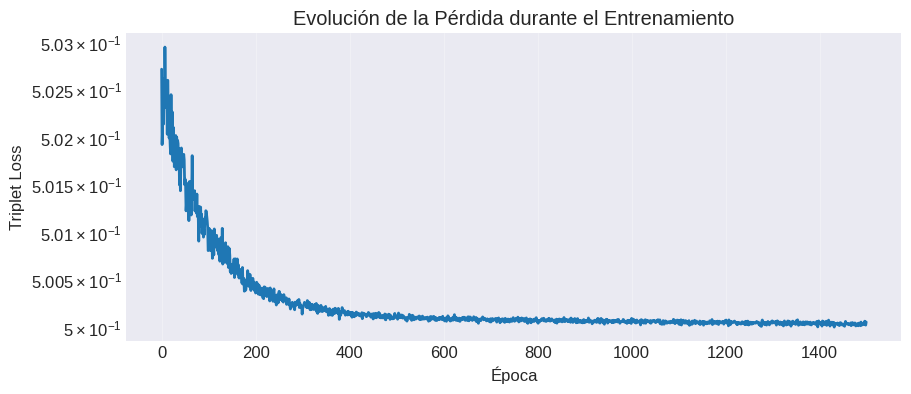

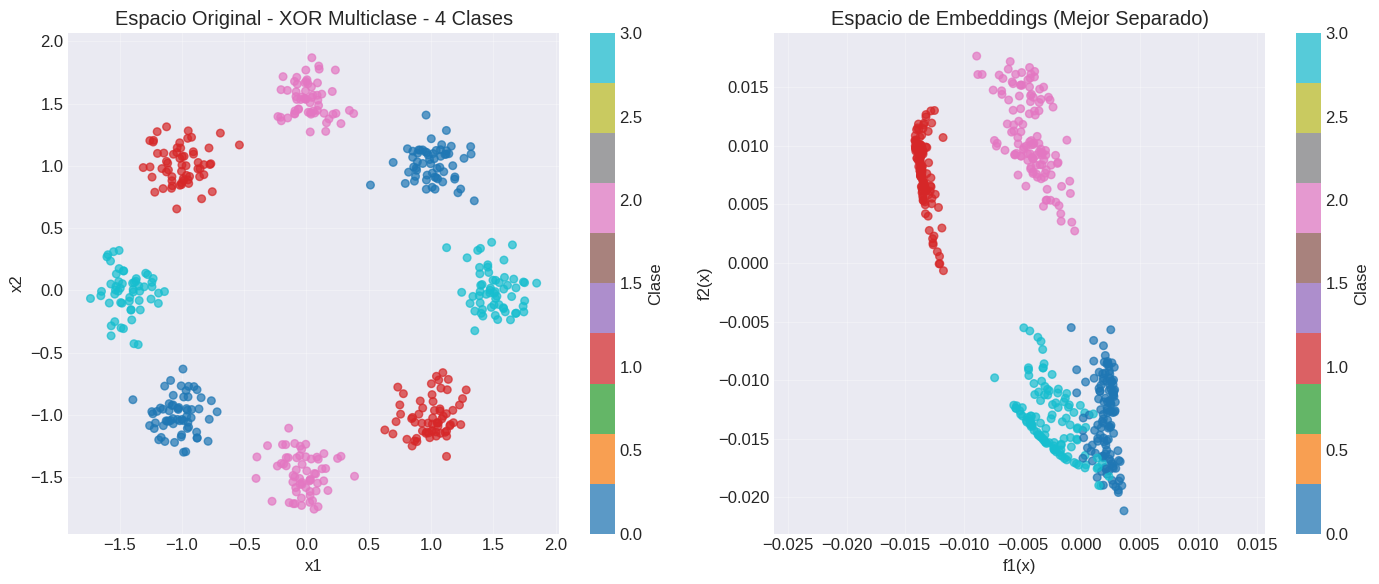

In [ ]:
# =============================================================================
# 7. ENTRENAMIENTO ITERATIVO
# =============================================================================

print("\nEntrenando...")
print("=" * 60)

for epoch in range(epochs):
    # Barajar datos
    idx = np.random.permutation(len(X_train))
    batch_size = min(64, len(X_train))
    X_batch = X_train[idx[:batch_size]]
    y_batch = y_train[idx[:batch_size]]

    # Forward
    emb = forward(X_batch, mu, gamma, W, b)

    # Triplet Loss y gradientes
    loss, grad_emb = triplet_loss(emb, y_batch)

    if loss > 0:
        # Calcular gradientes de parámetros
        Phi = rbf_features(X_batch, mu, gamma)

        # Gradiente W: ∂L/∂W = Σ δ_i · Φ(x_i)^T
        grad_W = np.zeros_like(W)
        for i in range(len(X_batch)):
            grad_W += np.outer(grad_emb[i], Phi[i])
        grad_W /= len(X_batch)

        # Gradiente b
        grad_b = np.mean(grad_emb, axis=0)

        # Gradientes μ y γ
        grad_mu = np.zeros_like(mu)
        grad_gamma = np.zeros_like(gamma)

        for k in range(K):
            for i in range(len(X_batch)):
                delta_dot_Wk = grad_emb[i] @ W[:, k]
                phi_ki = Phi[i, k]
                diff = X_batch[i] - mu[k]

                # ∂L/∂μ_k
                grad_mu[k] += delta_dot_Wk * 2 * gamma[k] * diff * phi_ki

                # ∂L/∂γ_k
                grad_gamma[k] += delta_dot_Wk * (-np.sum(diff**2)) * phi_ki

            grad_mu[k] /= len(X_batch)
            grad_gamma[k] /= len(X_batch)

        # Actualizar parámetros
        W -= lr * grad_W
        b -= lr * grad_b
        mu -= lr * grad_mu
        gamma -= lr * grad_gamma
        gamma = np.maximum(gamma, 0.01)  # γ > 0

    hist_loss.append(loss)

    if epoch % 10 == 0:
        print(f"Época {epoch:3d} | Loss: {loss:.4f}")

print("=" * 60)
print("Entrenamiento completado!")

# =============================================================================
# 8. VISUALIZAR EVOLUCIÓN DE LA PÉRDIDA
# =============================================================================

plt.figure(figsize=(10, 4))
plt.plot(hist_loss, linewidth=2)
plt.xlabel('Época')
plt.ylabel('Triplet Loss')
plt.title('Evolución de la Pérdida durante el Entrenamiento')
plt.grid(True, alpha=0.3)
plt.yscale('log' if min(hist_loss) > 0 else 'linear')
plt.show()

# =============================================================================
# 9. OBTENER EMBEDDINGS
# =============================================================================

emb_train = forward(X_train, mu, gamma, W, b)
emb_test = forward(X_test, mu, gamma, W, b)

# =============================================================================
# 10. VISUALIZAR EMBEDDINGS
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Espacio original
scatter1 = axes[0].scatter(X_train[:,0], X_train[:,1], c=y_train, cmap='tab10', s=30, alpha=0.7)
axes[0].set_title(f'Espacio Original - {titulo}')
axes[0].set_xlabel('x1')
axes[0].set_ylabel('x2')
axes[0].grid(True, alpha=0.3)
axes[0].axis('equal')
plt.colorbar(scatter1, ax=axes[0], label='Clase')

# Espacio de embeddings
scatter2 = axes[1].scatter(emb_train[:,0], emb_train[:,1], c=y_train, cmap='tab10', s=30, alpha=0.7)
axes[1].set_title('Espacio de Embeddings (Mejor Separado)')
axes[1].set_xlabel('f1(x)')
axes[1].set_ylabel('f2(x)')
axes[1].grid(True, alpha=0.3)
axes[1].axis('equal')
plt.colorbar(scatter2, ax=axes[1], label='Clase')

plt.tight_layout()
plt.show()

# =============================================================================
# 11. EVALUAR CON KNN
# =============================================================================

# KNN en espacio original
knn_orig = KNeighborsClassifier(n_neighbors=5)
knn_orig.fit(X_train, y_train)
y_pred_orig = knn_orig.predict(X_test)
acc_orig = accuracy_score(y_test, y_pred_orig)

# KNN en espacio de embeddings
knn_emb = KNeighborsClassifier(n_neighbors=5)
knn_emb.fit(emb_train, y_train)
y_pred_emb = knn_emb.predict(emb_test)
acc_emb = accuracy_score(y_test, y_pred_emb)


In [ ]:
# =============================================================================
# 16. IMPRIMIR PARÁMETROS CALCULADOS
# =============================================================================

print("\n" + "=" * 70)
print("PARÁMETROS DEL MODELO ENTRENADO")
print("=" * 70)

# 1. Centroides μ (K, 2)
print("\n1. CENTROIDES RBF (μ)")
print(f"   Shape: {mu.shape}")
print(f"   Número de funciones base: {K}")
print("   Valores (primeros 5 centroides):")
for k in range(min(5, K)):
    print(f"     μ[{k}] = [{mu[k,0]:.4f}, {mu[k,1]:.4f}]")
if K > 5:
    print(f"     ... y {K-5} centroides más")

# 2. Anchos γ (K,)
print("\n2. ANCHOS RBF (γ)")
print(f"   Shape: {gamma.shape}")
print(f"   Media: {np.mean(gamma):.4f}")
print(f"   Desviación estándar: {np.std(gamma):.4f}")
print(f"   Rango: [{np.min(gamma):.4f}, {np.max(gamma):.4f}]")
print("   Valores (primeros 5):")
for k in range(min(5, K)):
    print(f"     γ[{k}] = {gamma[k]:.4f}")
if K > 5:
    print(f"     ... y {K-5} anchos más")

# 3. Matriz de pesos W (d, K) donde d=2
print("\n3. MATRIZ DE PESOS W")
print(f"   Shape: {W.shape}")
print(f"   Media: {np.mean(W):.4f}")
print(f"   Desviación estándar: {np.std(W):.4f}")
print(f"   Rango: [{np.min(W):.4f}, {np.max(W):.4f}]")
print("   Matriz completa:")
print("   " + "-" * 50)
for i in range(W.shape[0]):
    fila = " ".join([f"{W[i,j]:8.4f}" for j in range(min(8, W.shape[1]))])
    if W.shape[1] > 8:
        fila += " ..."
    print(f"   W[{i}] = [{fila}]")
print("   " + "-" * 50)

# 4. Sesgo b (d,)
print("\n4. SESGO b")
print(f"   Shape: {b.shape}")
print(f"   b = [{b[0]:.4f}, {b[1]:.4f}]")

# 5. Resumen estadístico
print("\n5. RESUMEN ESTADÍSTICO")
print("-" * 50)
print(f"   Total de parámetros: {mu.size + gamma.size + W.size + b.size}")
print(f"   - Centroides μ: {mu.size} parámetros")
print(f"   - Anchos γ: {gamma.size} parámetros")
print(f"   - Pesos W: {W.size} parámetros")
print(f"   - Sesgo b: {b.size} parámetros")

# 6. Guardar parámetros en archivo (opcional)
print("\n6. GUARDAR PARÁMETROS")
print("-" * 50)
np.savez('modelo_rbf_params.npz',
         mu=mu, gamma=gamma, W=W, b=b,
         K=K, d=d, alpha=alpha)
print("   ✓ Parámetros guardados en 'modelo_rbf_params.npz'")

print("\n" + "=" * 70)


PARÁMETROS DEL MODELO ENTRENADO

1. CENTROIDES RBF (μ)
   Shape: (30, 2)
   Número de funciones base: 30
   Valores (primeros 5 centroides):
     μ[0] = [1.0285, 1.3035]
     μ[1] = [-0.1595, -1.3127]
     μ[2] = [-1.5487, 0.1067]
     μ[3] = [1.4037, -0.1444]
     μ[4] = [-1.0240, 1.1699]
     ... y 25 centroides más

2. ANCHOS RBF (γ)
   Shape: (30,)
   Media: 0.5418
   Desviación estándar: 0.0000
   Rango: [0.5418, 0.5419]
   Valores (primeros 5):
     γ[0] = 0.5418
     γ[1] = 0.5418
     γ[2] = 0.5418
     γ[3] = 0.5418
     γ[4] = 0.5418
     ... y 25 anchos más

3. MATRIZ DE PESOS W
   Shape: (2, 30)
   Media: -0.0003
   Desviación estándar: 0.0075
   Rango: [-0.0153, 0.0194]
   Matriz completa:
   --------------------------------------------------
   W[0] = [ -0.0015   0.0017   0.0097  -0.0051  -0.0085   0.0074  -0.0068   0.0117 ...]
   W[1] = [  0.0024   0.0058   0.0008  -0.0073   0.0141  -0.0153   0.0123   0.0037 ...]
   --------------------------------------------------

4.

In [ ]:
# =============================================================================
# 17. FUNCIÓN DE TRANSFORMACIÓN ENTRENADA
# =============================================================================

print("\n" + "=" * 70)
print("FUNCIÓN DE TRANSFORMACIÓN ENTRENADA")
print("=" * 70)

def transformar_punto(x, mu=mu, gamma=gamma, W=W, b=b):
    """
    Transforma un punto o conjunto de puntos usando el modelo entrenado.

    f_θ(x) = W · Φ(x) + b
    donde Φ_k(x) = exp(-γ_k * ||x - μ_k||²)

    Parámetros:
    -----------
    x : array-like de shape (n_puntos, 2) o (2,)
        Punto(s) en el espacio original

    Retorna:
    --------
    embedding : array de shape (n_puntos, 2) o (2,)
        Punto(s) transformado(s) al espacio de embeddings
    """
    # Convertir a numpy array si es necesario
    x = np.array(x, dtype=float)

    # Si es un solo punto, asegurar forma (1, 2)
    if x.ndim == 1:
        x = x.reshape(1, -1)

    # 1. Calcular funciones base RBF: Φ(x)
    n_puntos = x.shape[0]
    Phi = np.zeros((n_puntos, K))
    for k in range(K):
        diff = x - mu[k]  # (n_puntos, 2)
        sq_dist = np.sum(diff**2, axis=1)  # (n_puntos,)
        Phi[:, k] = np.exp(-gamma[k] * sq_dist)

    # 2. Transformación lineal: f(x) = W · Φ(x) + b
    embedding = Phi @ W.T + b  # (n_puntos, 2)

    # Si era un solo punto, devolver como vector
    if embedding.shape[0] == 1:
        return embedding[0]
    return embedding

def calcular_phi(x, mu=mu, gamma=gamma):
    """
    Calcula solo las funciones base RBF Φ(x) (para inspección).
    """
    x = np.array(x, dtype=float)
    if x.ndim == 1:
        x = x.reshape(1, -1)

    n_puntos = x.shape[0]
    Phi = np.zeros((n_puntos, K))
    for k in range(K):
        diff = x - mu[k]
        sq_dist = np.sum(diff**2, axis=1)
        Phi[:, k] = np.exp(-gamma[k] * sq_dist)

    if Phi.shape[0] == 1:
        return Phi[0]
    return Phi

print("\n✓ Función 'transformar_punto()' creada")
print("✓ Función 'calcular_phi()' creada")
print("\nUSO:")
print("  # Transformar un solo punto")
print("  punto = np.array([0.5, -0.3])")
print("  embedding = transformar_punto(punto)")
print()
print("  # Transformar varios puntos")
print("  puntos = np.array([[0.5, -0.3], [1.2, 0.8]])")
print("  embeddings = transformar_punto(puntos)")
print()
print("  # Obtener activaciones RBF")
print("  phi = calcular_phi(punto)")



FUNCIÓN DE TRANSFORMACIÓN ENTRENADA

✓ Función 'transformar_punto()' creada
✓ Función 'calcular_phi()' creada

USO:
  # Transformar un solo punto
  punto = np.array([0.5, -0.3])
  embedding = transformar_punto(punto)

  # Transformar varios puntos
  puntos = np.array([[0.5, -0.3], [1.2, 0.8]])
  embeddings = transformar_punto(puntos)

  # Obtener activaciones RBF
  phi = calcular_phi(punto)


In [ ]:
# =============================================================================
# 18. DEMOSTRACIÓN DE LA FUNCIÓN DE TRANSFORMACIÓN
# =============================================================================

print("\n" + "=" * 70)
print("DEMOSTRACIÓN DE LA TRANSFORMACIÓN")
print("=" * 70)

# Crear algunos puntos de prueba
puntos_prueba = np.array([
    [-1.0, -1.0],  # Centro de clase 0 (XOR)
    [1.0, 1.0],    # Centro de clase 0 (XOR)
    [-1.0, 1.0],   # Centro de clase 1 (XOR)
    [1.0, -1.0],   # Centro de clase 1 (XOR)
    [0.0, 0.0],    # Centro (punto incierto)
    [2.0, 0.0],    # Fuera del patrón
])

print("Puntos de prueba:")
for i, p in enumerate(puntos_prueba):
    print(f"  {i+1}. ({p[0]:.2f}, {p[1]:.2f})")

# Transformar puntos
embeddings_prueba = transformar_punto(puntos_prueba)

print("\nEmbeddings resultantes:")
for i, emb in enumerate(embeddings_prueba):
    print(f"  {i+1}. ({emb[0]:.4f}, {emb[1]:.4f})")



DEMOSTRACIÓN DE LA TRANSFORMACIÓN
Puntos de prueba:
  1. (-1.00, -1.00)
  2. (1.00, 1.00)
  3. (-1.00, 1.00)
  4. (1.00, -1.00)
  5. (0.00, 0.00)
  6. (2.00, 0.00)

Embeddings resultantes:
  1. (0.0019, -0.0156)
  2. (0.0024, -0.0111)
  3. (-0.0140, 0.0088)
  4. (-0.0136, 0.0071)
  5. (-0.0073, -0.0031)
  6. (-0.0014, -0.0136)


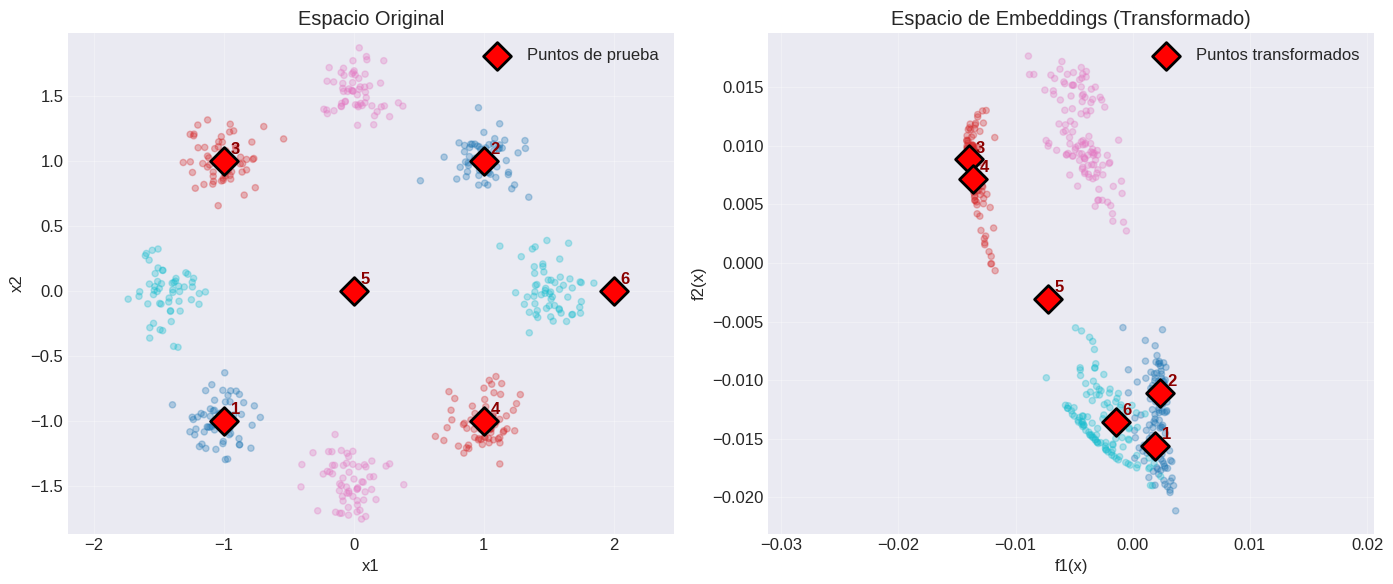

In [ ]:
# =============================================================================
# 19. VISUALIZAR TRANSFORMACIÓN DE PUNTOS DE PRUEBA
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Espacio original con puntos de prueba
ax1 = axes[0]
ax1.scatter(X_train[:,0], X_train[:,1], c=y_train, cmap='tab10', s=20, alpha=0.3)
ax1.scatter(puntos_prueba[:,0], puntos_prueba[:,1],
           c='red', s=200, marker='D',
           edgecolors='black', linewidths=2,
           label='Puntos de prueba')
# Etiquetar puntos
for i, p in enumerate(puntos_prueba):
    ax1.annotate(f'{i+1}', (p[0], p[1]),
                xytext=(5, 5), textcoords='offset points',
                fontsize=12, fontweight='bold', color='darkred')
ax1.set_title('Espacio Original')
ax1.set_xlabel('x1')
ax1.set_ylabel('x2')
ax1.legend()
ax1.grid(True, alpha=0.3)
ax1.axis('equal')

# Espacio de embeddings con puntos transformados
ax2 = axes[1]
ax2.scatter(emb_train[:,0], emb_train[:,1], c=y_train, cmap='tab10', s=20, alpha=0.3)
ax2.scatter(embeddings_prueba[:,0], embeddings_prueba[:,1],
           c='red', s=200, marker='D',
           edgecolors='black', linewidths=2,
           label='Puntos transformados')
# Etiquetar puntos transformados
for i, emb in enumerate(embeddings_prueba):
    ax2.annotate(f'{i+1}', (emb[0], emb[1]),
                xytext=(5, 5), textcoords='offset points',
                fontsize=12, fontweight='bold', color='darkred')
ax2.set_title('Espacio de Embeddings (Transformado)')
ax2.set_xlabel('f1(x)')
ax2.set_ylabel('f2(x)')
ax2.legend()
ax2.grid(True, alpha=0.3)
ax2.axis('equal')

plt.tight_layout()
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
ruta = "/content/drive/MyDrive/GaborFeatures_Dictionary25003000.pkl"

In [ ]:
import pickle

with open("/content/drive/MyDrive/GaborFeatures_Dictionary25003000.pkl", "rb") as f:
    datos = pickle.load(f)

In [ ]:
datos.keys()

dict_keys(['AA_1.jpg', 'AA_10.jpg', 'AA_11.jpg', 'AA_12.jpg', 'AA_13.jpg', 'AA_14.jpg', 'AA_15.jpg', 'AA_16.jpg', 'AA_17.jpg', 'AA_18.jpg', 'AA_19.jpg', 'AA_2.jpg', 'AA_20.jpg', 'AA_3.jpg', 'AA_4.jpg', 'AA_5.jpg', 'AA_6.jpg', 'AA_7.jpg', 'AA_8.jpg', 'AA_9.jpg', 'AB_1.jpg', 'AB_10.jpg', 'AB_11.jpg', 'AB_12.jpg', 'AB_13.jpg', 'AB_14.jpg', 'AB_15.jpg', 'AB_16.jpg', 'AB_17.jpg', 'AB_18.jpg', 'AB_19.jpg', 'AB_2.jpg', 'AB_20.jpg', 'AB_3.jpg', 'AB_4.jpg', 'AB_5.jpg', 'AB_6.jpg', 'AB_7.jpg', 'AB_8.jpg', 'AB_9.jpg', 'AC_1.jpg', 'AC_10.jpg', 'AC_11.jpg', 'AC_12.jpg', 'AC_13.jpg', 'AC_14.jpg', 'AC_15.jpg', 'AC_16.jpg', 'AC_17.jpg', 'AC_18.jpg', 'AC_19.jpg', 'AC_2.jpg', 'AC_20.jpg', 'AC_3.jpg', 'AC_4.jpg', 'AC_5.jpg', 'AC_6.jpg', 'AC_7.jpg', 'AC_8.jpg', 'AC_9.jpg', 'AD_1.jpg', 'AD_10.jpg', 'AD_11.jpg', 'AD_12.jpg', 'AD_13.jpg', 'AD_14.jpg', 'AD_15.jpg', 'AD_16.jpg', 'AD_17.jpg', 'AD_18.jpg', 'AD_19.jpg', 'AD_2.jpg', 'AD_20.jpg', 'AD_3.jpg', 'AD_4.jpg', 'AD_5.jpg', 'AD_6.jpg', 'AD_7.jpg', 'AD_8.jpg

In [ ]:
datos['C_15.jpg']

[np.float64(90.2644424177495),
 np.float64(83.67219318317203),
 np.float64(62.97561508440779),
 np.float64(65.37836720689074),
 np.float64(255.17240598356446),
 np.float64(208.86260572550722),
 np.float64(58.87905653587128),
 np.float64(52.97819703929074),
 np.float64(56.17346668146943),
 np.float64(69.57848550530241),
 np.float64(19.53354352253248),
 np.float64(22.45594887336389),
 np.float64(183.7391620698272),
 np.float64(173.81254189357426),
 np.float64(21.420929884159943),
 np.float64(16.79585707813147),
 np.float64(49.73812924068964),
 np.float64(104.86062720258084),
 np.float64(6.366739815482419),
 np.float64(6.355010763413632),
 np.float64(167.27114804417383),
 np.float64(157.7391536752499),
 np.float64(4.782677695124747),
 np.float64(4.020606535282696)]

INSPECCIÓN INICIAL DE DATOS
Número total de muestras: 3000
Primeras 10 claves: ['AA_1.jpg', 'AA_10.jpg', 'AA_11.jpg', 'AA_12.jpg', 'AA_13.jpg', 'AA_14.jpg', 'AA_15.jpg', 'AA_16.jpg', 'AA_17.jpg', 'AA_18.jpg']

Ejemplo - Clave: AA_1.jpg
Tipo de dato: <class 'list'>
Longitud del vector: 24
Primeros 5 valores: [np.float64(98.58780205113769), np.float64(86.74573074712201), np.float64(56.358584784687324), np.float64(36.834396024616645), np.float64(197.60806022714488)]

EXTRACCIÓN DE ETIQUETAS
Número de clases únicas: 165
Primeras 10 clases: ['A', 'AA', 'AB', 'AC', 'AD', 'AE', 'AF', 'AG', 'AH', 'AI']

Distribución de clases:
  A: 20 muestras
  AA: 20 muestras
  AB: 20 muestras
  AC: 20 muestras
  AD: 20 muestras
  AE: 8 muestras
  AF: 18 muestras
  AG: 20 muestras
  AH: 20 muestras
  AI: 15 muestras

CREANDO ARRAYS X e Y
Total de clases: 165

Extrayendo datos...
  - Muestras: 3000
  - Dimensión original: 24

✓ Arrays creados:
  - X shape: (3000, 24)
  - y shape: (3000,)
  - Rango de y: 0 a 1

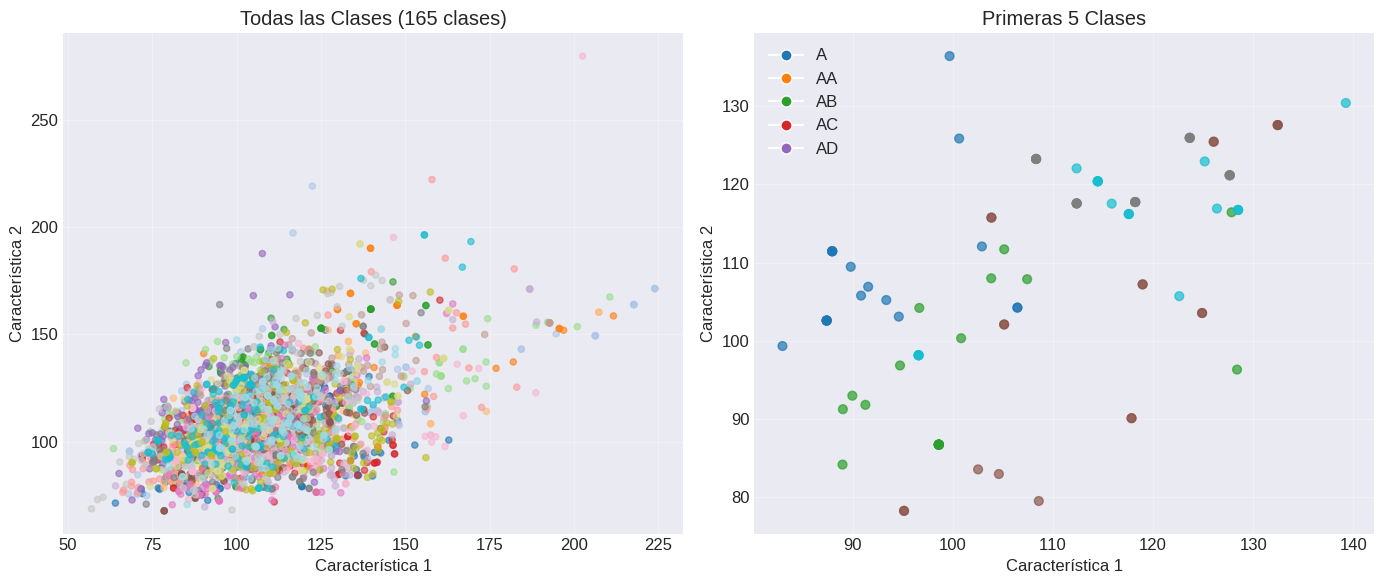


ESTADÍSTICAS - PRIMERAS 5 CLASES

Clase A:
  - Muestras: 20
  - Media: [92.39, 108.57]
  - Std:   [6.84, 8.58]
  - Rango x1: [82.97, 106.44]
  - Rango x2: [99.34, 136.39]

Clase AA:
  - Muestras: 20
  - Media: [100.63, 94.80]
  - Std:   [10.36, 9.70]
  - Rango x1: [88.97, 128.39]
  - Rango x2: [84.19, 116.43]

Clase AB:
  - Muestras: 20
  - Media: [114.83, 103.69]
  - Std:   [12.13, 17.40]
  - Rango x1: [95.11, 132.45]
  - Rango x2: [78.29, 127.57]

Clase AC:
  - Muestras: 20
  - Media: [118.04, 121.13]
  - Std:   [7.08, 3.22]
  - Rango x1: [108.31, 127.65]
  - Rango x2: [117.56, 125.94]

Clase AD:
  - Muestras: 20
  - Media: [116.20, 114.43]
  - Std:   [11.80, 9.23]
  - Rango x1: [96.57, 139.26]
  - Rango x2: [98.16, 130.40]

GUARDANDO DATOS PREPARADOS
✓ Datos guardados en 'datos_preparados.npz'

Para cargar los datos en otro script:
  data = np.load('datos_preparados.npz')
  X = data['X_5clases']
  y = data['y_5clases']
  clases = data['nombres_clases']

RESUMEN DE PREPARACIÓN DE DA

In [ ]:
# =============================================================================
# PREPARACIÓN DE DATOS DESDE DICCIONARIO
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt

# =============================================================================
# 1. ENTENDER LA ESTRUCTURA DE LOS DATOS
# =============================================================================

print("=" * 60)
print("INSPECCIÓN INICIAL DE DATOS")
print("=" * 60)

# Ver las primeras claves del diccionario
claves = list(datos.keys())
print(f"Número total de muestras: {len(claves)}")
print(f"Primeras 10 claves: {claves[:10]}")

# Ver la estructura de un dato
clave_ejemplo = claves[0]
vector = datos[clave_ejemplo]
print(f"\nEjemplo - Clave: {clave_ejemplo}")
print(f"Tipo de dato: {type(vector)}")
print(f"Longitud del vector: {len(vector)}")
print(f"Primeros 5 valores: {vector[:5]}")

# =============================================================================
# 2. EXTRAER ETIQUETAS (CLASES) DESDE LOS NOMBRES DE ARCHIVO
# =============================================================================

print("\n" + "=" * 60)
print("EXTRACCIÓN DE ETIQUETAS")
print("=" * 60)

# Las clases se identifican por las primeras letras antes del '_'
# Ej: 'AA_1.jpg' → clase 'AA'
def extraer_clase(nombre_archivo):
    """Extrae la clase del nombre del archivo (ej: 'AA' de 'AA_1.jpg')"""
    return nombre_archivo.split('_')[0]

# Extraer todas las clases
clases = [extraer_clase(clave) for clave in claves]
clases_unicas = sorted(set(clases))

print(f"Número de clases únicas: {len(clases_unicas)}")
print(f"Primeras 10 clases: {clases_unicas[:10]}")

# Contar muestras por clase
from collections import Counter
conteo_clases = Counter(clases)
print(f"\nDistribución de clases:")
for clase in sorted(conteo_clases.keys())[:10]:  # Mostrar solo primeras 10
    print(f"  {clase}: {conteo_clases[clase]} muestras")

# =============================================================================
# 3. CREAR ARRAYS X (CARACTERÍSTICAS) E Y (ETIQUETAS NUMÉRICAS)
# =============================================================================

print("\n" + "=" * 60)
print("CREANDO ARRAYS X e Y")
print("=" * 60)

# Mapear clases a números
clase_a_numero = {clase: i for i, clase in enumerate(clases_unicas)}
print(f"Total de clases: {len(clase_a_numero)}")

# Crear arrays
n_muestras = len(claves)
dimension = len(datos[claves[0]])  # Dimensión del vector

print(f"\nExtrayendo datos...")
print(f"  - Muestras: {n_muestras}")
print(f"  - Dimensión original: {dimension}")

# Inicializar arrays
X = np.zeros((n_muestras, dimension))
y = np.zeros(n_muestras, dtype=int)

# Llenar arrays
for i, clave in enumerate(claves):
    X[i, :] = datos[clave]
    clase = extraer_clase(clave)
    y[i] = clase_a_numero[clase]

print(f"\n✓ Arrays creados:")
print(f"  - X shape: {X.shape}")
print(f"  - y shape: {y.shape}")
print(f"  - Rango de y: {y.min()} a {y.max()}")

# =============================================================================
# 4. REDUCIR A SOLO PRIMERAS 2 CARACTERÍSTICAS PARA VISUALIZACIÓN
# =============================================================================

print("\n" + "=" * 60)
print("REDUCCIÓN A 2 DIMENSIONES PARA VISUALIZACIÓN")
print("=" * 60)

# Tomar solo las primeras 2 características
X_2d = X[:, :2]  # Usar columnas 0 y 1

print(f"✓ X_2d shape: {X_2d.shape} (usando primeras 2 características)")
print(f"  - Característica 1: media={np.mean(X_2d[:,0]):.2f}, std={np.std(X_2d[:,0]):.2f}")
print(f"  - Característica 2: media={np.mean(X_2d[:,1]):.2f}, std={np.std(X_2d[:,1]):.2f}")

# =============================================================================
# 5. FILTRAR SOLO PRIMERAS 5 CLASES PARA VISUALIZACIÓN CLARA
# =============================================================================

print("\n" + "=" * 60)
print("FILTRANDO PRIMERAS 5 CLASES")
print("=" * 60)

# Seleccionar las primeras 5 clases
primeras_5_clases = clases_unicas[:5]
print(f"Clases seleccionadas: {primeras_5_clases}")

# Filtrar datos
mask_5 = np.isin(y, [clase_a_numero[clase] for clase in primeras_5_clases])
X_5clases = X_2d[mask_5]
y_5clases = y[mask_5]

# Re-mapear etiquetas para que sean 0,1,2,3,4
clases_seleccionadas = sorted(set(y_5clases))
mapeo_nuevo = {old: new for new, old in enumerate(clases_seleccionadas)}
y_5clases_nuevo = np.array([mapeo_nuevo[val] for val in y_5clases])

print(f"\n✓ Datos filtrados:")
print(f"  - Muestras: {len(X_5clases)}")
print(f"  - Clases: {len(np.unique(y_5clases_nuevo))}")
print(f"  - Distribución:")
for i, clase in enumerate(primeras_5_clases):
    count = np.sum(y_5clases_nuevo == i)
    print(f"    {clase}: {count} muestras")

# =============================================================================
# 6. VISUALIZAR DATOS - PRIMERAS 5 CLASES
# =============================================================================

print("\n" + "=" * 60)
print("VISUALIZACIÓN DE DATOS")
print("=" * 60)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Gráfico 1: Todas las clases (con colores)
ax1 = axes[0]
scatter1 = ax1.scatter(X_2d[:, 0], X_2d[:, 1],
                       c=y, cmap='tab20', s=20, alpha=0.6)
ax1.set_title(f'Todas las Clases ({len(clases_unicas)} clases)')
ax1.set_xlabel('Característica 1')
ax1.set_ylabel('Característica 2')
ax1.grid(True, alpha=0.3)
# No mostrar colorbar para no saturar

# Gráfico 2: Solo primeras 5 clases
ax2 = axes[1]
scatter2 = ax2.scatter(X_5clases[:, 0], X_5clases[:, 1],
                       c=y_5clases_nuevo, cmap='tab10', s=40, alpha=0.7)
ax2.set_title(f'Primeras 5 Clases')
ax2.set_xlabel('Característica 1')
ax2.set_ylabel('Característica 2')
ax2.grid(True, alpha=0.3)

# Añadir leyenda con nombres de clases
legend_elements = []
for i, clase in enumerate(primeras_5_clases):
    legend_elements.append(plt.Line2D([0], [0], marker='o', color='w',
                                       markerfacecolor=plt.cm.tab10(i/10),
                                       markersize=8, label=clase))
ax2.legend(handles=legend_elements, loc='best')

plt.tight_layout()
plt.show()

# =============================================================================
# 7. ESTADÍSTICAS BÁSICAS DE LAS PRIMERAS 5 CLASES
# =============================================================================

print("\n" + "=" * 60)
print("ESTADÍSTICAS - PRIMERAS 5 CLASES")
print("=" * 60)

for i, clase in enumerate(primeras_5_clases):
    mask_clase = (y_5clases_nuevo == i)
    datos_clase = X_5clases[mask_clase]

    print(f"\nClase {clase}:")
    print(f"  - Muestras: {len(datos_clase)}")
    print(f"  - Media: [{np.mean(datos_clase[:,0]):.2f}, {np.mean(datos_clase[:,1]):.2f}]")
    print(f"  - Std:   [{np.std(datos_clase[:,0]):.2f}, {np.std(datos_clase[:,1]):.2f}]")
    print(f"  - Rango x1: [{np.min(datos_clase[:,0]):.2f}, {np.max(datos_clase[:,0]):.2f}]")
    print(f"  - Rango x2: [{np.min(datos_clase[:,1]):.2f}, {np.max(datos_clase[:,1]):.2f}]")

# =============================================================================
# 8. GUARDAR DATOS PREPARADOS
# =============================================================================

print("\n" + "=" * 60)
print("GUARDANDO DATOS PREPARADOS")
print("=" * 60)

# Guardar en formato numpy para reutilizar
np.savez('datos_preparados.npz',
         X_5clases=X_5clases,
         y_5clases=y_5clases_nuevo,
         nombres_clases=primeras_5_clases,
         X_full=X_2d,
         y_full=y,
         clases_unicas=clases_unicas)

print("✓ Datos guardados en 'datos_preparados.npz'")
print("\nPara cargar los datos en otro script:")
print("  data = np.load('datos_preparados.npz')")
print("  X = data['X_5clases']")
print("  y = data['y_5clases']")
print("  clases = data['nombres_clases']")

# =============================================================================
# 9. RESUMEN FINAL
# =============================================================================

print("\n" + "=" * 60)
print("RESUMEN DE PREPARACIÓN DE DATOS")
print("=" * 60)
print(f"\n✓ Datos procesados:")
print(f"  - Diccionario original: {len(datos)} muestras")
print(f"  - Dimensión vector: {dimension}")
print(f"  - Total clases: {len(clases_unicas)}")
print(f"  - Clases seleccionadas: {len(primeras_5_clases)}")
print(f"  - Muestras seleccionadas: {len(X_5clases)}")
print(f"\n✓ Listo para el siguiente paso:")
print(f"  - Tenemos X (características) e y (etiquetas)")
print(f"  - Los datos están en 2D para visualización")
print(f"  - Las clases están numeradas 0,1,2,3,4")
print(f"  - Los nombres de clases originales: {primeras_5_clases}")

# Mostrar ejemplo de cómo acceder a los datos preparados
print("\n" + "=" * 60)
print("EJEMPLO DE ACCESO A DATOS")
print("=" * 60)
print("\n# Para usar los datos:")
print("X = X_5clases  # Matriz de características (n, 2)")
print("y = y_5clases_nuevo  # Etiquetas (0,1,2,3,4)")
print("nombres = primeras_5_clases  # ['AA', 'AB', 'AC', 'AD', 'AE']")
print("\n# Primera muestra:")
print(f"  X[0] = {X_5clases[0]}")
print(f"  y[0] = {y_5clases_nuevo[0]} ({primeras_5_clases[y_5clases_nuevo[0]]})")

In [ ]:
# =============================================================================
# ENTRENAMIENTO DEL MODELO RBF CON TUS DATOS REALES
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# =============================================================================
# 1. CARGAR DATOS PREPARADOS
# =============================================================================

print("=" * 60)
print("CARGANDO DATOS PREPARADOS")
print("=" * 60)

# Cargar datos guardados anteriormente
data = np.load('datos_preparados.npz')
X = data['X_5clases']  # (n, 2)
y = data['y_5clases']  # (n,)
nombres_clases = data['nombres_clases']  # ['AA', 'AB', 'AC', 'AD', 'AE']

print(f"Datos cargados:")
print(f"  - Muestras: {len(X)}")
print(f"  - Clases: {len(np.unique(y))}")
print(f"  - Nombres clases: {list(nombres_clases)}")
print(f"  - Dimensión: {X.shape[1]}")

# =============================================================================
# 2. NORMALIZAR DATOS (OPCIONAL PERO RECOMENDADO)
# =============================================================================

print("\n" + "=" * 60)
print("NORMALIZANDO DATOS")
print("=" * 60)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"✓ Datos normalizados:")
print(f"  - Media: {np.mean(X_scaled, axis=0)}")
print(f"  - Std: {np.std(X_scaled, axis=0)}")

# =============================================================================
# 3. DIVIDIR EN ENTRENAMIENTO Y PRUEBA
# =============================================================================

print("\n" + "=" * 60)
print("DIVIDIENDO DATOS")
print("=" * 60)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.25, random_state=42, stratify=y
)

print(f"Entrenamiento: {len(X_train)} muestras")
print(f"Prueba: {len(X_test)} muestras")
print(f"Distribución entrenamiento: {dict(zip(*np.unique(y_train, return_counts=True)))}")

# =============================================================================
# 4. PARÁMETROS DEL MODELO
# =============================================================================

print("\n" + "=" * 60)
print("CONFIGURANDO PARÁMETROS")
print("=" * 60)

K = 30          # Número de funciones RBF
d = 2           # Dimensión del embedding (2D para visualizar)
alpha = 0.5     # Margen Triplet Loss
lr = 0.05       # Tasa de aprendizaje
epochs = 200    # Iteraciones
batch_size = 32

print(f"Parámetros:")
print(f"  - RBFs: {K}")
print(f"  - Embedding dim: {d}")
print(f"  - Margen: {alpha}")
print(f"  - Learning rate: {lr}")
print(f"  - Épocas: {epochs}")

# =============================================================================
# 5. INICIALIZAR PARÁMETROS
# =============================================================================

print("\n" + "=" * 60)
print("INICIALIZANDO PARÁMETROS")
print("=" * 60)

# Centroides: K-means
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
kmeans.fit(X_train)
mu = kmeans.cluster_centers_.copy()  # (K, 2)

# Anchos: basados en distancia promedio
distancias = []
for i in range(K):
    for j in range(i+1, K):
        distancias.append(np.linalg.norm(mu[i] - mu[j]))
sigma = np.mean(distancias) / 2.0 if distancias else 0.5
gamma = np.ones(K) / (2.0 * sigma**2)
gamma = np.clip(gamma, 0.1, 10.0)  # (K,)

# Pesos y sesgo
W = np.random.randn(d, K) * 0.01   # (2, K)
b = np.zeros(d)                    # (2,)

print(f"✓ Parámetros inicializados:")
print(f"  - μ shape: {mu.shape}")
print(f"  - γ shape: {gamma.shape}")
print(f"  - W shape: {W.shape}")
print(f"  - b shape: {b.shape}")

# =============================================================================
# 6. FUNCIONES AUXILIARES
# =============================================================================

def rbf_features(X, mu, gamma):
    """Calcula Φ(x) = exp(-γ_k * ||x - μ_k||²)"""
    n = len(X)
    Phi = np.zeros((n, K))
    for k in range(K):
        diff = X - mu[k]
        sq_dist = np.sum(diff**2, axis=1)
        Phi[:, k] = np.exp(-gamma[k] * sq_dist)
    return Phi

def forward(X, mu, gamma, W, b):
    """f_θ(x) = W * Φ(x) + b"""
    Phi = rbf_features(X, mu, gamma)
    return Phi @ W.T + b

def triplet_loss(emb, y, alpha):
    """Triplet Loss con Batch Hard Mining"""
    B = len(emb)
    loss = 0.0
    grad_emb = np.zeros_like(emb)

    # Matriz de distancias al cuadrado
    diff = emb[:, np.newaxis, :] - emb[np.newaxis, :, :]
    sq_dist = np.sum(diff**2, axis=2)

    for a in range(B):
        # Positivo más lejano
        same = np.where(y == y[a])[0]
        if len(same) < 2:
            continue
        p_idx = same[np.argmax(sq_dist[a, same])]
        d_ap = sq_dist[a, p_idx]

        # Negativo más cercano
        diff_cls = np.where(y != y[a])[0]
        if len(diff_cls) == 0:
            continue
        n_idx = diff_cls[np.argmin(sq_dist[a, diff_cls])]
        d_an = sq_dist[a, n_idx]

        # Pérdida
        l = max(0, d_ap - d_an + alpha)
        loss += l

        # Gradientes
        if l > 0:
            grad_emb[a] += 2 * (emb[n_idx] - emb[p_idx])
            grad_emb[p_idx] += 2 * (emb[p_idx] - emb[a])
            grad_emb[n_idx] += 2 * (emb[a] - emb[n_idx])

    return loss / B, grad_emb / B



CARGANDO DATOS PREPARADOS
Datos cargados:
  - Muestras: 100
  - Clases: 5
  - Nombres clases: [np.str_('A'), np.str_('AA'), np.str_('AB'), np.str_('AC'), np.str_('AD')]
  - Dimensión: 2

NORMALIZANDO DATOS
✓ Datos normalizados:
  - Media: [3.75477427e-15 2.73392420e-15]
  - Std: [1. 1.]

DIVIDIENDO DATOS
Entrenamiento: 75 muestras
Prueba: 25 muestras
Distribución entrenamiento: {np.int64(0): np.int64(15), np.int64(1): np.int64(15), np.int64(2): np.int64(15), np.int64(3): np.int64(15), np.int64(4): np.int64(15)}

CONFIGURANDO PARÁMETROS
Parámetros:
  - RBFs: 30
  - Embedding dim: 2
  - Margen: 0.5
  - Learning rate: 0.05
  - Épocas: 200

INICIALIZANDO PARÁMETROS
✓ Parámetros inicializados:
  - μ shape: (30, 2)
  - γ shape: (30,)
  - W shape: (2, 30)
  - b shape: (2,)


In [ ]:
pochs = 4000


ENTRENANDO MODELO
Época   0 | Loss: 0.5010
Época  20 | Loss: 0.5013
Época  40 | Loss: 0.5007
Época  60 | Loss: 0.5010
Época  80 | Loss: 0.5008
Época 100 | Loss: 0.5005
Época 120 | Loss: 0.5002
Época 140 | Loss: 0.5005
Época 160 | Loss: 0.5004
Época 180 | Loss: 0.5002
✓ Entrenamiento completado!


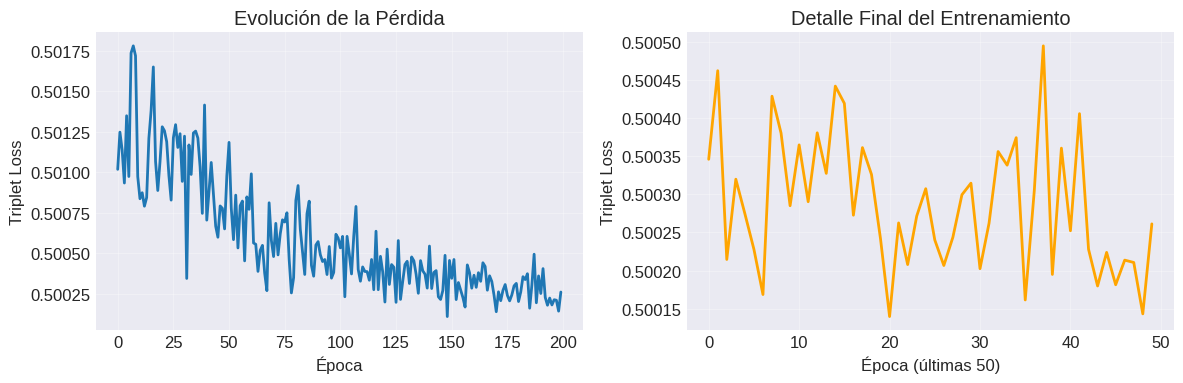

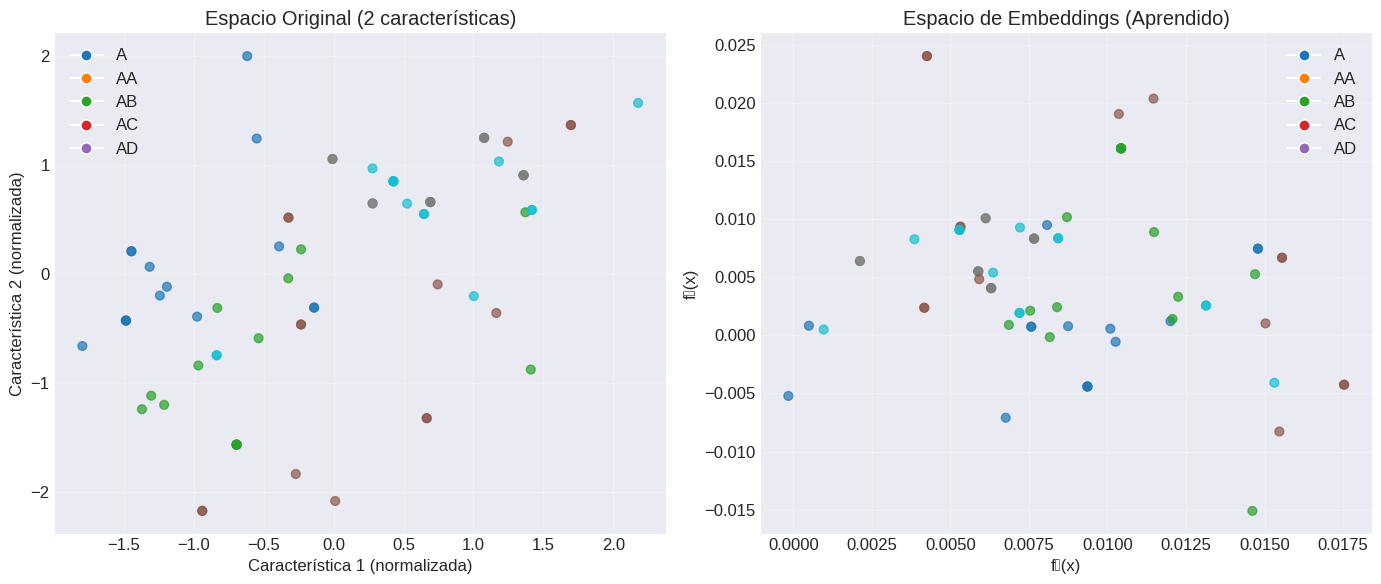


EVALUACIÓN DEL MODELO
Precisión en espacio original: 0.4400
Precisión en espacio de embeddings: 0.4800
Mejora: 4.00%

Reporte de clasificación (Embeddings):
              precision    recall  f1-score   support

           A       0.83      1.00      0.91         5
          AA       0.38      0.60      0.46         5
          AB       0.33      0.20      0.25         5
          AC       0.50      0.60      0.55         5
          AD       0.00      0.00      0.00         5

    accuracy                           0.48        25
   macro avg       0.41      0.48      0.43        25
weighted avg       0.41      0.48      0.43        25



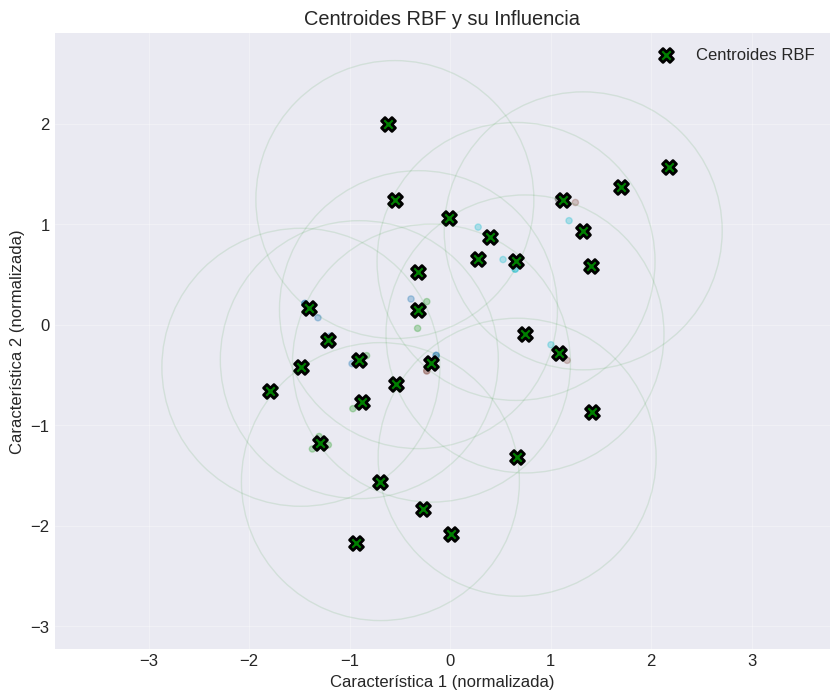

In [ ]:
# =============================================================================
# 7. ENTRENAMIENTO ITERATIVO
# =============================================================================

print("\n" + "=" * 60)
print("ENTRENANDO MODELO")
print("=" * 60)

hist_loss = []

for epoch in range(epochs):
    # Barajar datos
    idx = np.random.permutation(len(X_train))
    batch_size_actual = min(batch_size, len(X_train))
    X_batch = X_train[idx[:batch_size_actual]]
    y_batch = y_train[idx[:batch_size_actual]]

    # Forward
    emb = forward(X_batch, mu, gamma, W, b)

    # Triplet Loss y gradientes
    loss, grad_emb = triplet_loss(emb, y_batch, alpha)

    if loss > 0:
        # Calcular gradientes de parámetros
        Phi = rbf_features(X_batch, mu, gamma)

        # Gradiente W: ∂L/∂W = Σ δ_i · Φ(x_i)^T
        grad_W = np.zeros_like(W)
        for i in range(len(X_batch)):
            grad_W += np.outer(grad_emb[i], Phi[i])
        grad_W /= len(X_batch)

        # Gradiente b
        grad_b = np.mean(grad_emb, axis=0)

        # Gradientes μ y γ
        grad_mu = np.zeros_like(mu)
        grad_gamma = np.zeros_like(gamma)

        for k in range(K):
            for i in range(len(X_batch)):
                delta_dot_Wk = grad_emb[i] @ W[:, k]
                phi_ki = Phi[i, k]
                diff = X_batch[i] - mu[k]

                # ∂L/∂μ_k
                grad_mu[k] += delta_dot_Wk * 2 * gamma[k] * diff * phi_ki

                # ∂L/∂γ_k
                grad_gamma[k] += delta_dot_Wk * (-np.sum(diff**2)) * phi_ki

            grad_mu[k] /= len(X_batch)
            grad_gamma[k] /= len(X_batch)

        # Actualizar parámetros
        W -= lr * grad_W
        b -= lr * grad_b
        mu -= lr * grad_mu
        gamma -= lr * grad_gamma
        gamma = np.maximum(gamma, 0.01)  # γ > 0

    hist_loss.append(loss)

    if epoch % 20 == 0:
        print(f"Época {epoch:3d} | Loss: {loss:.4f}")

print("=" * 60)
print("✓ Entrenamiento completado!")

# =============================================================================
# 8. VISUALIZAR EVOLUCIÓN DE LA PÉRDIDA
# =============================================================================

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(hist_loss, linewidth=2)
plt.xlabel('Época')
plt.ylabel('Triplet Loss')
plt.title('Evolución de la Pérdida')
plt.grid(True, alpha=0.3)
if min(hist_loss) > 0.01:
    plt.yscale('linear')
else:
    plt.yscale('log')

# Zoom a las últimas épocas
plt.subplot(1, 2, 2)
plt.plot(hist_loss[-50:], linewidth=2, color='orange')
plt.xlabel('Época (últimas 50)')
plt.ylabel('Triplet Loss')
plt.title('Detalle Final del Entrenamiento')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# =============================================================================
# 9. OBTENER EMBEDDINGS
# =============================================================================

emb_train = forward(X_train, mu, gamma, W, b)
emb_test = forward(X_test, mu, gamma, W, b)

# =============================================================================
# 10. VISUALIZAR EMBEDDINGS
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Espacio original
ax1 = axes[0]
scatter1 = ax1.scatter(X_train[:, 0], X_train[:, 1],
                       c=y_train, cmap='tab10', s=40, alpha=0.7)
ax1.set_title(f'Espacio Original (2 características)')
ax1.set_xlabel('Característica 1 (normalizada)')
ax1.set_ylabel('Característica 2 (normalizada)')
ax1.grid(True, alpha=0.3)

# Crear leyenda con nombres de clases
legend_elements = []
for i, nombre in enumerate(nombres_clases):
    legend_elements.append(plt.Line2D([0], [0], marker='o', color='w',
                                       markerfacecolor=plt.cm.tab10(i/10),
                                       markersize=8, label=nombre))
ax1.legend(handles=legend_elements, loc='best')

# Espacio de embeddings
ax2 = axes[1]
scatter2 = ax2.scatter(emb_train[:, 0], emb_train[:, 1],
                       c=y_train, cmap='tab10', s=40, alpha=0.7)
ax2.set_title('Espacio de Embeddings (Aprendido)')
ax2.set_xlabel('f₁(x)')
ax2.set_ylabel('f₂(x)')
ax2.grid(True, alpha=0.3)
ax2.legend(handles=legend_elements, loc='best')

plt.tight_layout()
plt.show()

# =============================================================================
# 11. EVALUAR CON KNN
# =============================================================================

print("\n" + "=" * 60)
print("EVALUACIÓN DEL MODELO")
print("=" * 60)

# KNN en espacio original
knn_orig = KNeighborsClassifier(n_neighbors=5)
knn_orig.fit(X_train, y_train)
y_pred_orig = knn_orig.predict(X_test)
acc_orig = accuracy_score(y_test, y_pred_orig)

# KNN en espacio de embeddings
knn_emb = KNeighborsClassifier(n_neighbors=5)
knn_emb.fit(emb_train, y_train)
y_pred_emb = knn_emb.predict(emb_test)
acc_emb = accuracy_score(y_test, y_pred_emb)

print(f"Precisión en espacio original: {acc_orig:.4f}")
print(f"Precisión en espacio de embeddings: {acc_emb:.4f}")
print(f"Mejora: {(acc_emb - acc_orig)*100:.2f}%")

# Matriz de confusión
from sklearn.metrics import confusion_matrix, classification_report
print("\nReporte de clasificación (Embeddings):")
print(classification_report(y_test, y_pred_emb, target_names=nombres_clases))

# =============================================================================
# 12. VISUALIZAR CENTROIDES RBF
# =============================================================================

plt.figure(figsize=(10, 8))

# Datos originales
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train,
           cmap='tab10', s=20, alpha=0.3)

# Centroides RBF
plt.scatter(mu[:, 0], mu[:, 1], c='green', s=100, marker='X',
           edgecolors='black', linewidths=2, label='Centroides RBF')

# Círculos de influencia (opcional)
for k in range(min(K, 10)):  # Mostrar solo primeros 10 para no saturar
    radius = np.sqrt(1.0 / gamma[k]) if gamma[k] > 0 else 0.5
    circle = plt.Circle(mu[k], radius, color='green', alpha=0.1, fill=False)
    plt.gca().add_patch(circle)

plt.xlabel('Característica 1 (normalizada)')
plt.ylabel('Característica 2 (normalizada)')
plt.title('Centroides RBF y su Influencia')
plt.legend()
plt.grid(True, alpha=0.3)
plt.axis('equal')
plt.show()


In [64]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [65]:
import pickle

ruta = '/content/drive/MyDrive/GaborFeatures_Dictionary003000.pkl'

with open(ruta, 'rb') as f:
    data = pickle.load(f)

print(type(data))

<class 'dict'>


In [66]:
print("Tipo de objeto:", type(data))

if isinstance(data, dict):
    print("Número de elementos:", len(data))
    print("Primeras claves:", list(data.keys())[:10])

elif isinstance(data, (list, tuple)):
    print("Número de elementos:", len(data))
    print("Primeros elementos:", data[:5])

else:
    print(data)

Tipo de objeto: <class 'dict'>
Número de elementos: 3000
Primeras claves: ['AA_1.jpg', 'AA_10.jpg', 'AA_11.jpg', 'AA_12.jpg', 'AA_13.jpg', 'AA_14.jpg', 'AA_15.jpg', 'AA_16.jpg', 'AA_17.jpg', 'AA_18.jpg']


In [67]:
import pandas as pd

df = pd.DataFrame.from_dict(data, orient='index')

display(df.head())
print("Dimensiones:", df.shape)

,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
AA_1.jpg,98.587802,86.745731,56.358585,36.834396,197.608060,136.276753,52.395570,32.062011,65.348715,66.511676,...,20.552723,13.481989,71.452360,104.233713,8.401132,4.834997,170.172671,159.762891,7.858873,5.182043
AA_10.jpg,88.966905,84.193557,51.564241,39.888123,187.393759,141.326698,47.304950,32.308756,53.909220,60.695156,...,18.268532,12.619065,59.123453,100.058671,5.869432,3.970952,170.338179,159.495509,5.131338,3.393768
AA_11.jpg,91.252315,91.830931,47.130514,40.372304,194.325836,149.540178,51.444049,36.339900,55.269524,65.842245,...,15.559509,13.159775,57.505157,101.307417,5.777942,4.010542,169.262009,159.190330,5.283858,3.440455
AA_12.jpg,96.639765,104.209909,47.630940,37.634061,196.893628,149.292290,53.426817,36.046112,60.193631,70.937716,...,22.916943,18.148518,57.757103,101.112273,6.612139,4.460182,169.867327,160.142545,5.566534,4.599890
AA_13.jpg,89.947971,92.995640,50.414484,39.064229,189.015450,147.932514,40.398781,27.612294,54.657868,70.284450,...,19.119533,16.849820,52.958874,100.838511,4.504610,3.778899,168.950984,158.805548,5.306167,4.453209


Dimensiones: (3000, 24)


In [68]:
import pandas as pd

df = pd.DataFrame.from_dict(data, orient='index')

df = df.reset_index()
df = df.rename(columns={'index': 'ID'})

display(df.head())
print("Dimensiones:", df.shape)

,ID,0,1,2,3,4,5,6,7,8,...,14,15,16,17,18,19,20,21,22,23
0,AA_1.jpg,98.587802,86.745731,56.358585,36.834396,197.608060,136.276753,52.395570,32.062011,65.348715,...,20.552723,13.481989,71.452360,104.233713,8.401132,4.834997,170.172671,159.762891,7.858873,5.182043
1,AA_10.jpg,88.966905,84.193557,51.564241,39.888123,187.393759,141.326698,47.304950,32.308756,53.909220,...,18.268532,12.619065,59.123453,100.058671,5.869432,3.970952,170.338179,159.495509,5.131338,3.393768
2,AA_11.jpg,91.252315,91.830931,47.130514,40.372304,194.325836,149.540178,51.444049,36.339900,55.269524,...,15.559509,13.159775,57.505157,101.307417,5.777942,4.010542,169.262009,159.190330,5.283858,3.440455
3,AA_12.jpg,96.639765,104.209909,47.630940,37.634061,196.893628,149.292290,53.426817,36.046112,60.193631,...,22.916943,18.148518,57.757103,101.112273,6.612139,4.460182,169.867327,160.142545,5.566534,4.599890
4,AA_13.jpg,89.947971,92.995640,50.414484,39.064229,189.015450,147.932514,40.398781,27.612294,54.657868,...,19.119533,16.849820,52.958874,100.838511,4.504610,3.778899,168.950984,158.805548,5.306167,4.453209


Dimensiones: (3000, 25)


In [69]:

# 1. Extraer la clave de los dos primeros caracteres de ID
df['clave'] = df['ID'].str[:2]

# 2. Contar cuántas filas tiene cada clave
conteo = df['clave'].value_counts()

# Conservar únicamente las claves con al menos 5 filas
claves_validas = conteo[conteo >= 5].index

# 3. Filtrar y seleccionar las primeras 5 filas de cada clave
df_filtrado = (
    df[df['clave'].isin(claves_validas)]
    .groupby('clave', sort=False)
    .head(5)
    .drop(columns=['clave'])
    .reset_index(drop=True)
)

# Mostrar resultados
display(df_filtrado.head(10))
print("Dimensiones originales:", df.shape)
print("Dimensiones filtradas:", df_filtrado.shape)
print("Claves conservadas:", df_filtrado['ID'].str[:2].nunique())


,ID,0,1,2,3,4,5,6,7,8,...,14,15,16,17,18,19,20,21,22,23
0,AA_1.jpg,98.587802,86.745731,56.358585,36.834396,197.608060,136.276753,52.395570,32.062011,65.348715,...,20.552723,13.481989,71.452360,104.233713,8.401132,4.834997,170.172671,159.762891,7.858873,5.182043
1,AA_10.jpg,88.966905,84.193557,51.564241,39.888123,187.393759,141.326698,47.304950,32.308756,53.909220,...,18.268532,12.619065,59.123453,100.058671,5.869432,3.970952,170.338179,159.495509,5.131338,3.393768
2,AA_11.jpg,91.252315,91.830931,47.130514,40.372304,194.325836,149.540178,51.444049,36.339900,55.269524,...,15.559509,13.159775,57.505157,101.307417,5.777942,4.010542,169.262009,159.190330,5.283858,3.440455
3,AA_12.jpg,96.639765,104.209909,47.630940,37.634061,196.893628,149.292290,53.426817,36.046112,60.193631,...,22.916943,18.148518,57.757103,101.112273,6.612139,4.460182,169.867327,160.142545,5.566534,4.599890
4,AA_13.jpg,89.947971,92.995640,50.414484,39.064229,189.015450,147.932514,40.398781,27.612294,54.657868,...,19.119533,16.849820,52.958874,100.838511,4.504610,3.778899,168.950984,158.805548,5.306167,4.453209
5,AB_1.jpg,105.117916,102.095392,46.483915,42.552042,239.673632,201.546194,45.379295,56.376756,71.234917,...,19.059347,28.189023,51.112786,103.906695,3.877829,4.191462,167.781034,158.573236,3.620044,3.845175
6,AB_10.jpg,126.052351,125.448270,35.930696,29.857848,241.850214,190.219139,41.440718,56.201264,85.369831,...,15.141034,16.294566,57.998577,101.224474,4.035224,3.444502,168.344632,158.507008,4.998338,6.797159
7,AB_11.jpg,118.954225,107.219633,47.446928,32.402182,218.248877,173.700994,47.552121,37.217792,75.761158,...,22.254759,19.276253,55.477445,97.292484,4.735450,3.508327,169.167497,158.701916,4.781611,2.991578
8,AB_12.jpg,118.954225,107.219633,47.446928,32.402182,218.248877,173.700994,47.552121,37.217792,75.761158,...,22.254759,19.276253,55.477445,97.292484,4.735450,3.508327,169.167497,158.701916,4.781611,2.991578
9,AB_13.jpg,108.578149,79.543745,46.442995,33.582344,240.303895,180.146626,54.099140,42.824756,76.844158,...,21.904374,21.576059,56.718997,101.652734,5.044761,4.627593,169.488883,158.964415,4.337753,3.524231


Dimensiones originales: (3000, 26)
Dimensiones filtradas: (810, 25)
Claves conservadas: 162


In [70]:
# Crear una copia del DataFrame filtrado
DATOS = df_filtrado.copy()

# Reemplazar ID por los dos primeros caracteres
DATOS['ID'] = DATOS['ID'].str[:2]

# Mostrar resultados
display(DATOS.head(10))
print("Dimensiones de DATOS:", DATOS.shape)

,ID,0,1,2,3,4,5,6,7,8,...,14,15,16,17,18,19,20,21,22,23
0,AA,98.587802,86.745731,56.358585,36.834396,197.608060,136.276753,52.395570,32.062011,65.348715,...,20.552723,13.481989,71.452360,104.233713,8.401132,4.834997,170.172671,159.762891,7.858873,5.182043
1,AA,88.966905,84.193557,51.564241,39.888123,187.393759,141.326698,47.304950,32.308756,53.909220,...,18.268532,12.619065,59.123453,100.058671,5.869432,3.970952,170.338179,159.495509,5.131338,3.393768
2,AA,91.252315,91.830931,47.130514,40.372304,194.325836,149.540178,51.444049,36.339900,55.269524,...,15.559509,13.159775,57.505157,101.307417,5.777942,4.010542,169.262009,159.190330,5.283858,3.440455
3,AA,96.639765,104.209909,47.630940,37.634061,196.893628,149.292290,53.426817,36.046112,60.193631,...,22.916943,18.148518,57.757103,101.112273,6.612139,4.460182,169.867327,160.142545,5.566534,4.599890
4,AA,89.947971,92.995640,50.414484,39.064229,189.015450,147.932514,40.398781,27.612294,54.657868,...,19.119533,16.849820,52.958874,100.838511,4.504610,3.778899,168.950984,158.805548,5.306167,4.453209
5,AB,105.117916,102.095392,46.483915,42.552042,239.673632,201.546194,45.379295,56.376756,71.234917,...,19.059347,28.189023,51.112786,103.906695,3.877829,4.191462,167.781034,158.573236,3.620044,3.845175
6,AB,126.052351,125.448270,35.930696,29.857848,241.850214,190.219139,41.440718,56.201264,85.369831,...,15.141034,16.294566,57.998577,101.224474,4.035224,3.444502,168.344632,158.507008,4.998338,6.797159
7,AB,118.954225,107.219633,47.446928,32.402182,218.248877,173.700994,47.552121,37.217792,75.761158,...,22.254759,19.276253,55.477445,97.292484,4.735450,3.508327,169.167497,158.701916,4.781611,2.991578
8,AB,118.954225,107.219633,47.446928,32.402182,218.248877,173.700994,47.552121,37.217792,75.761158,...,22.254759,19.276253,55.477445,97.292484,4.735450,3.508327,169.167497,158.701916,4.781611,2.991578
9,AB,108.578149,79.543745,46.442995,33.582344,240.303895,180.146626,54.099140,42.824756,76.844158,...,21.904374,21.576059,56.718997,101.652734,5.044761,4.627593,169.488883,158.964415,4.337753,3.524231


Dimensiones de DATOS: (810, 25)


In [221]:
DATOS=DATOS.head(200)
DATOS.shape

(200, 25)

In [222]:
DATOS.head()

,ID,0,1,2,3,4,5,6,7,8,...,14,15,16,17,18,19,20,21,22,23
0,AA,98.587802,86.745731,56.358585,36.834396,197.608060,136.276753,52.395570,32.062011,65.348715,...,20.552723,13.481989,71.452360,104.233713,8.401132,4.834997,170.172671,159.762891,7.858873,5.182043
1,AA,88.966905,84.193557,51.564241,39.888123,187.393759,141.326698,47.304950,32.308756,53.909220,...,18.268532,12.619065,59.123453,100.058671,5.869432,3.970952,170.338179,159.495509,5.131338,3.393768
2,AA,91.252315,91.830931,47.130514,40.372304,194.325836,149.540178,51.444049,36.339900,55.269524,...,15.559509,13.159775,57.505157,101.307417,5.777942,4.010542,169.262009,159.190330,5.283858,3.440455
3,AA,96.639765,104.209909,47.630940,37.634061,196.893628,149.292290,53.426817,36.046112,60.193631,...,22.916943,18.148518,57.757103,101.112273,6.612139,4.460182,169.867327,160.142545,5.566534,4.599890
4,AA,89.947971,92.995640,50.414484,39.064229,189.015450,147.932514,40.398781,27.612294,54.657868,...,19.119533,16.849820,52.958874,100.838511,4.504610,3.778899,168.950984,158.805548,5.306167,4.453209


In [223]:
import copy
import numpy as np
import pandas as pd

# ==========================================
# HIPERPARÁMETROS
# ==========================================

D = 24                  # Número de características de entrada
K = 12                   # Número de funciones RBF
d = D // 3               # Dimensión del embedding

NUM_CLIENTS = 8          # Número de clientes
ROUNDS = 250              # Rondas federadas
LOCAL_EPOCHS = 30         # Épocas locales por ronda
BATCH_SIZE = 32          # Minibatch de tripletas
LEARNING_RATE = 1e-3     # Tasa de aprendizaje SGD
ALPHA = 1.0              # Margen de Triplet Loss

SAMPLES_PER_IDENTITY = 5
RANDOM_SEED = 2026


rng = np.random.default_rng(RANDOM_SEED)

print(f"Dimensión de entrada D: {D}")
print(f"Dimensión del embedding d: {d}")
print(f"Número de funciones RBF K: {K}")
print(f"Dimensión de W: ({d}, {K})")
print(f"Dimensión de mu: ({K}, {D})")

Dimensión de entrada D: 24
Dimensión del embedding d: 8
Número de funciones RBF K: 12
Dimensión de W: (8, 12)
Dimensión de mu: (12, 24)


In [122]:
import numpy as np
import pandas as pd

# Parámetros del conjunto sintético
#np.random.seed(42)

N_identidades = 20
muestras_por_identidad = 5
D = 6  # Número de variables de entrada

# Centros de las identidades
centros = np.random.normal(
    loc=0.0,
    scale=3.0,
    size=(N_identidades, D)
)

datos = []

for identidad in range(N_identidades):
    for _ in range(muestras_por_identidad):
        # Generar una muestra alrededor del centro de la identidad
        x = centros[identidad] + np.random.normal(
            loc=0.0,
            scale=0.5,
            size=D
        )

        fila = {
            "id": identidad,
            **{f"feature_{j+1}": x[j] for j in range(D)}
        }

        datos.append(fila)

# Crear DataFrame y guardar CSV
df = pd.DataFrame(datos)
df.to_csv("datos.csv", index=False)

print(df.head())
print("\nDimensiones:", df.shape)
print("Número de identidades:", df["id"].nunique())
print("\nMuestras por identidad:")
print(df.groupby("id").size().value_counts())

   id  feature_1  feature_2  feature_3  feature_4  feature_5  feature_6
0   0   1.434913  -6.053807  -2.201811  -0.786880   2.079593   6.644459
1   0   1.674790  -5.989132  -3.051708  -0.896058   2.450292   7.976543
2   0   1.466563  -4.984709  -2.274381  -0.998595   2.654189   8.677995
3   0   1.360293  -6.195663  -3.847337  -0.901412   2.292118   7.475710
4   0   1.752386  -7.107789  -2.471354  -0.270021   1.813911   7.715321

Dimensiones: (100, 7)
Número de identidades: 20

Muestras por identidad:
5    20
Name: count, dtype: int64


In [224]:
# ==========================================
# CARGA DE DATOS
# ==========================================

#  ruta real del archivo.
df = pd.read_csv("datos.csv")
df = DATOS
# La primera columna contiene el identificador.
id_col = df.columns[0]

# Verificar que existan suficientes características.
assert df.shape[1] >= D + 1, (
    f"Se esperaban al menos {D} características, "
    f"pero se encontraron {df.shape[1] - 1}."
)

# Seleccionar exactamente D características.
feature_cols = list(df.columns[1:D + 1])

# Separar identificadores y vectores de características.
identity_ids = df[id_col].to_numpy()
X = df[feature_cols].to_numpy(dtype=np.float64)

assert X.shape[1] == D
assert np.isfinite(X).all(), "Hay valores NaN o infinitos."

print("Muestras totales:", len(X))
print("Identidades totales:", len(np.unique(identity_ids)))
print("Forma de X:", X.shape)

Muestras totales: 200
Identidades totales: 40
Forma de X: (200, 24)


In [225]:
D

24

In [226]:
# ==========================================
# PARTICIÓN FEDERADA POR IDENTIDAD
# ==========================================

def split_clients_by_identity(
    X,
    identity_ids,
    num_clients,
    samples_per_identity=5,
    seed=2026
):
    rng_local = np.random.default_rng(2026)
    unique_ids = np.unique(identity_ids)

    # Verificar cinco muestras por identidad.
    for identity in unique_ids:
        count = np.sum(identity_ids == identity)
        if count != samples_per_identity:
            raise ValueError(
                f"La identidad {identity} tiene {count} muestras; "
                f"se esperaban {samples_per_identity}."
            )

    # Todos los clientes deben recibir el mismo número
    # de identidades.
    if len(unique_ids) % num_clients != 0:
        raise ValueError(
            "El número de identidades debe ser divisible "
            "entre el número de clientes."
        )

    shuffled_ids = rng_local.permutation(unique_ids)
    ids_by_client = np.array_split(shuffled_ids, num_clients)

    clients = []

    for client_ids in ids_by_client:
        mask = np.isin(identity_ids, client_ids)

        X_i = X[mask]
        ids_i = identity_ids[mask]

        clients.append({
            "X": X_i,
            "ids": ids_i,
            "N_i": len(client_ids)
        })

    return clients


clients = split_clients_by_identity(
    X,
    identity_ids,
    NUM_CLIENTS,
    samples_per_identity=SAMPLES_PER_IDENTITY,
    seed=RANDOM_SEED
)

for i, client in enumerate(clients):
    print(
        f"Cliente {i + 1}: "
        f"{client['N_i']} identidades, "
        f"{len(client['X'])} muestras"
    )

Cliente 1: 5 identidades, 25 muestras
Cliente 2: 5 identidades, 25 muestras
Cliente 3: 5 identidades, 25 muestras
Cliente 4: 5 identidades, 25 muestras
Cliente 5: 5 identidades, 25 muestras
Cliente 6: 5 identidades, 25 muestras
Cliente 7: 5 identidades, 25 muestras
Cliente 8: 5 identidades, 25 muestras


In [256]:
# ==========================================
# INICIALIZACIÓN DEL MODELO RBF
# ==========================================

def initialize_parameters(X_init, D, K, d, seed=2026):
    rng_local = np.random.default_rng(seed)

    # Centros iniciales seleccionados del cliente
    # designado para la inicialización.
    if len(X_init) < K:
        raise ValueError(
            "El cliente de inicialización debe tener "
            "al menos K muestras."
        )

    selected = rng_local.choice(
        len(X_init), size=K, replace=False
    )
    mu = X_init[selected].copy()          # (K, D)

    W = rng_local.normal(
        loc=0.0, scale=1.0 / np.sqrt(K), size=(d, K)
    )                                     # (d, K)

    b = np.zeros(d, dtype=np.float64)     # (d,)

    gamma = np.full(K, 0.001 / D, dtype=np.float64) # O un valor mucho más bajo

    gamma = np.full(K, 1.0 / D, dtype=np.float64)                                     # (K,)

    return {
        "W": W,
        "b": b,
        "mu": mu,
        "gamma": gamma
    }


# Recolectar una muestra pequeña de todos los clientes
X_all_samples = np.vstack([client["X"][:2] for client in clients])

theta_global = initialize_parameters(
    X_init=X_all_samples,
    D=D, K=K, d=d, seed=RANDOM_SEED
)

for name, parameter in theta_global.items():
    print(f"{name}: {parameter.shape}")

W: (8, 12)
b: (8,)
mu: (12, 24)
gamma: (12,)


In [257]:
# ==========================================
# TRANSFORMACIÓN RBF
# ==========================================

def rbf_features(X, mu, gamma):
    """
    X:     (B, D)
    mu:    (K, D)
    gamma: (K,)

    Retorna Phi: (B, K)
    """
    diff = X[:, None, :] - mu[None, :, :]  # (B, K, D)
    squared_distances = np.sum(diff**2, axis=2)  # (B, K)

    with np.errstate(over="raise", invalid="raise"):
        Phi = np.exp(
            -squared_distances * gamma[None, :]
        )

    return Phi


def transform(X, theta):
    """
    X: (B, D)
    Retorna embeddings de dimensión (B, d).
    """
    Phi = rbf_features(
        X, theta["mu"], theta["gamma"]
    )

    return Phi @ theta["W"].T + theta["b"]


# Prueba de dimensiones.
X_test = clients[0]["X"][:3]
Z_test = transform(X_test, theta_global)

print("Entrada:", X_test.shape)
print("Embedding:", Z_test.shape)

Entrada: (3, 24)
Embedding: (3, 8)


In [258]:
# ==========================================
# CONSTRUCCIÓN DE TRIPLETAS
# ==========================================

def build_triplets(X, ids, seed=None):
    """
    Genera exactamente una tripleta por ancla.

    Retorna:
        A: anclas,    (M, D)
        P: positivos, (M, D)
        N: negativos, (M, D)
    """
    rng_local = np.random.default_rng(seed)

    groups = {
        identity: np.flatnonzero(ids == identity)
        for identity in np.unique(ids)
    }

    if len(groups) < 2:
        raise ValueError(
            "Se necesitan al menos dos identidades por cliente."
        )

    # Todas las muestras son posibles anclas.
    anchors_idx = np.arange(len(X))

    # Identidades alternativas para seleccionar negativos.
    all_ids = list(groups.keys())

    positive_idx = np.empty(len(X), dtype=int)
    negative_idx = np.empty(len(X), dtype=int)

    for a_idx in anchors_idx:
        anchor_id = ids[a_idx]

        # Positivos: misma identidad, excluyendo el ancla.
        candidates_p = groups[anchor_id]
        candidates_p = candidates_p[candidates_p != a_idx]

        positive_idx[a_idx] = rng_local.choice(candidates_p)

        # Negativo: identidad diferente elegida al azar.
        candidates_ids = [
            identity for identity in all_ids
            if identity != anchor_id
        ]
        negative_id = rng_local.choice(candidates_ids)

        # Muestra aleatoria de esa identidad.
        negative_idx[a_idx] = rng_local.choice(
            groups[negative_id]
        )

    A = X[anchors_idx]
    P = X[positive_idx]
    N = X[negative_idx]

    return A, P, N


A, P, N = build_triplets(
    clients[0]["X"],
    clients[0]["ids"],
    seed=RANDOM_SEED
)

print("Número de anclas:", len(A))
print("Forma de A:", A.shape)
print("Forma de P:", P.shape)
print("Forma de N:", N.shape)

Número de anclas: 25
Forma de A: (25, 24)
Forma de P: (25, 24)
Forma de N: (25, 24)


In [259]:
# ==========================================
# TRIPLET LOSS
# ==========================================

def triplet_loss(theta, A, P, N, alpha):
    Za = transform(A, theta)
    Zp = transform(P, theta)
    Zn = transform(N, theta)

    d_ap = np.sum((Za - Zp)**2, axis=1)
    d_an = np.sum((Za - Zn)**2, axis=1)

    losses = np.maximum(0.0, d_ap - d_an + alpha)

    return np.mean(losses)

In [260]:
# ==========================================
# GRADIENTES ANALÍTICOS
# ==========================================

def triplet_loss_and_gradients(theta, A, P, N, alpha):
    """
    Calcula la Triplet Loss media y los gradientes de:
        W:     (d, K)
        b:     (d,)
        mu:    (K, D)
        gamma: (K,)
    """

    W = theta["W"]
    b = theta["b"]
    mu = theta["mu"]
    gamma = theta["gamma"]

    B = len(A)
    if B == 0:
        raise ValueError("El minibatch está vacío.")

    # --------------------------------------
    # 1. Activaciones RBF
    # --------------------------------------
    Phi_a = rbf_features(A, mu, gamma)
    Phi_p = rbf_features(P, mu, gamma)
    Phi_n = rbf_features(N, mu, gamma)

    # --------------------------------------
    # 2. Embeddings
    # --------------------------------------
    Za = Phi_a @ W.T + b
    Zp = Phi_p @ W.T + b
    Zn = Phi_n @ W.T + b

    # --------------------------------------
    # 3. Triplet Loss
    # --------------------------------------
    delta_ap = Za - Zp
    delta_an = Za - Zn

    d_ap = np.sum(delta_ap**2, axis=1)
    d_an = np.sum(delta_an**2, axis=1)

    margins = d_ap - d_an + alpha
    active = (margins > 0).astype(np.float64)

    loss = np.mean(np.maximum(0.0, margins))

    # --------------------------------------
    # 4. Gradientes respecto de embeddings
    # --------------------------------------
    # La división entre B corresponde a la
    # pérdida media del minibatch.
    gZa = (
        2.0 * (Zn - Zp) * active[:, None] / B
    )
    gZp = (
        -2.0 * delta_ap * active[:, None] / B
    )
    gZn = (
        2.0 * delta_an * active[:, None] / B
    )

    # --------------------------------------
    # 5. Gradientes respecto de W y b
    # --------------------------------------
    grad_W = (
        gZa.T @ Phi_a
        + gZp.T @ Phi_p
        + gZn.T @ Phi_n
    )

    grad_b = np.sum(gZa + gZp + gZn, axis=0)

    # --------------------------------------
    # 6. Gradientes respecto de Phi
    # --------------------------------------
    gPhi_a = gZa @ W
    gPhi_p = gZp @ W
    gPhi_n = gZn @ W

    # --------------------------------------
    # 7. Distancias de las entradas a mu
    # --------------------------------------
    diff_a = A[:, None, :] - mu[None, :, :]
    diff_p = P[:, None, :] - mu[None, :, :]
    diff_n = N[:, None, :] - mu[None, :, :]

    r2_a = np.sum(diff_a**2, axis=2)
    r2_p = np.sum(diff_p**2, axis=2)
    r2_n = np.sum(diff_n**2, axis=2)

    # --------------------------------------
    # 8. Gradientes respecto de mu
    # d phi / d mu = 2 gamma phi (x - mu)
    # --------------------------------------
    grad_mu = (
        np.einsum(
            "bk,bk,bkd->kd",
            gPhi_a, Phi_a,
            2.0 * gamma[None, :, None] * diff_a
        )
        + np.einsum(
            "bk,bk,bkd->kd",
            gPhi_p, Phi_p,
            2.0 * gamma[None, :, None] * diff_p
        )
        + np.einsum(
            "bk,bk,bkd->kd",
            gPhi_n, Phi_n,
            2.0 * gamma[None, :, None] * diff_n
        )
    )

    # --------------------------------------
    # 9. Gradientes respecto de gamma
    # d phi / d gamma = -||x-mu||^2 phi
    # --------------------------------------
    grad_gamma = (
        np.sum(-gPhi_a * r2_a * Phi_a, axis=0)
        + np.sum(-gPhi_p * r2_p * Phi_p, axis=0)
        + np.sum(-gPhi_n * r2_n * Phi_n, axis=0)
    )

    gradients = {
        "W": grad_W,
        "b": grad_b,
        "mu": grad_mu,
        "gamma": grad_gamma
    }

    return loss, gradients

In [261]:
# ==========================================
# ACTUALIZACIÓN SGD
# ==========================================

def sgd_update(theta, gradients, learning_rate):
    for key in theta:
        theta[key] -= learning_rate * gradients[key]

    return theta


def train_local(
    theta_global,
    X_i,
    ids_i,
    epochs,
    batch_size,
    learning_rate,
    alpha,
    seed=None
):
    rng_local = np.random.default_rng(seed)

    # Copia independiente del modelo recibido.
    theta_local = copy.deepcopy(theta_global)

    # Una tripleta por ancla, generada al inicio
    # de la ronda local.
    A, P, N = build_triplets(X_i, ids_i, seed=seed)
    num_triplets = len(A)

    epoch_losses = []

    for epoch in range(epochs):
        permutation = rng_local.permutation(num_triplets)
        batch_losses = []

        for start in range(0, num_triplets, batch_size):
            idx = permutation[start:start + batch_size]

            A_batch = A[idx]
            P_batch = P[idx]
            N_batch = N[idx]

            loss, gradients = triplet_loss_and_gradients(
                theta_local,
                A_batch,
                P_batch,
                N_batch,
                alpha
            )

            theta_local = sgd_update(
                theta_local,
                gradients,
                learning_rate
            )

            batch_losses.append(loss)

        epoch_loss = float(np.mean(batch_losses))
        epoch_losses.append(epoch_loss)

    return theta_local, epoch_losses

In [262]:
# ==========================================
# AGREGACIÓN FEDAVG
# ==========================================

def fedavg(local_parameters):
    """
    Promedia cada grupo de parámetros entre clientes.
    Todos los modelos deben tener las mismas dimensiones.
    """
    num_clients = len(local_parameters)

    if num_clients == 0:
        raise ValueError("No hay parámetros locales para agregar.")

    theta_global = {}

    for key in local_parameters[0]:
        theta_global[key] = np.mean(
            np.stack(
                [theta[key] for theta in local_parameters],
                axis=0
            ),
            axis=0
        )

    return theta_global

In [263]:
# ==========================================
# ENTRENAMIENTO FEDERADO COMPLETO
# ==========================================

history = []

for t in range(ROUNDS):

    local_parameters = []
    round_losses = []

    print(f"\nRonda federada {t + 1}/{ROUNDS}")

    # --------------------------------------
    # Entrenamiento local de cada cliente
    # --------------------------------------
    for i, client in enumerate(clients):

        theta_local, losses = train_local(
            theta_global=theta_global,
            X_i=client["X"],
            ids_i=client["ids"],
            epochs=LOCAL_EPOCHS,
            batch_size=BATCH_SIZE,
            learning_rate=LEARNING_RATE,
            alpha=ALPHA,
            seed=RANDOM_SEED + t * NUM_CLIENTS + i
        )

        local_parameters.append(theta_local)
        round_losses.append(losses[-1])

        print(
            f"  Cliente {i + 1}: "
            f"pérdida local final = {losses[-1]:.6f}"
        )

    # --------------------------------------
    # Agregación global
    # --------------------------------------
    theta_global = fedavg(local_parameters)

    mean_local_loss = float(np.mean(round_losses))
    history.append({
        "round": t + 1,
        "mean_local_loss": mean_local_loss
    })

    print(
        f"  Promedio de pérdidas locales: "
        f"{mean_local_loss:.6f}"
    )

# Modelo final
theta_final = copy.deepcopy(theta_global)

print("\nEntrenamiento federado terminado.")
print("Dimensiones finales:")

for key, value in theta_final.items():
    print(f"{key}: {value.shape}")


Ronda federada 1/250
  Cliente 1: pérdida local final = 1.034451
  Cliente 2: pérdida local final = 0.962898
  Cliente 3: pérdida local final = 0.910737
  Cliente 4: pérdida local final = 1.000000
  Cliente 5: pérdida local final = 0.997285
  Cliente 6: pérdida local final = 0.812305
  Cliente 7: pérdida local final = 0.979891
  Cliente 8: pérdida local final = 0.974633
  Promedio de pérdidas locales: 0.959025

Ronda federada 2/250
  Cliente 1: pérdida local final = 1.023801
  Cliente 2: pérdida local final = 1.018317
  Cliente 3: pérdida local final = 0.977461
  Cliente 4: pérdida local final = 1.000000
  Cliente 5: pérdida local final = 1.043379
  Cliente 6: pérdida local final = 0.969265
  Cliente 7: pérdida local final = 0.998850
  Cliente 8: pérdida local final = 1.000000
  Promedio de pérdidas locales: 1.003884

Ronda federada 3/250
  Cliente 1: pérdida local final = 1.029639
  Cliente 2: pérdida local final = 0.962875
  Cliente 3: pérdida local final = 0.961551
  Cliente 4: pér

In [264]:
# ==========================================
# OBTENER EMBEDDINGS
# ==========================================

# Ejemplo: transformar las muestras del primer cliente.
X_client = clients[0]["X"]
ids_client = clients[0]["ids"]

Z_client = transform(X_client, theta_final)

print("Matriz de entrada:", X_client.shape)
print("Matriz de embeddings:", Z_client.shape)

# Asociar cada embedding con su identidad.
embeddings_df = pd.DataFrame(
    Z_client,
    columns=[f"embedding_{j + 1}" for j in range(d)]
)

embeddings_df.insert(0, "Id", ids_client)

print(embeddings_df.head())

Matriz de entrada: (25, 24)
Matriz de embeddings: (25, 8)
   Id   embedding_1   embedding_2   embedding_3   embedding_4   embedding_5  \
0  AJ  4.131046e-02 -1.961769e-01  1.514483e-01  4.615380e-01 -2.903356e-01   
1  AJ -1.360910e-01  2.334049e-01  1.765223e-01 -6.740051e-02 -3.609593e-01   
2  AJ -3.348086e-12  5.742184e-12  4.342769e-12 -1.658174e-12 -8.880253e-12   
3  AJ -3.348086e-12  5.742184e-12  4.342769e-12 -1.658174e-12 -8.880253e-12   
4  AJ  2.317825e-19  2.333444e-19  2.643222e-20  3.032211e-19 -1.017265e-19   

    embedding_6   embedding_7   embedding_8  
0  3.370465e-01 -2.090313e-01 -2.908639e-01  
1  4.521029e-01 -5.276510e-01  3.921799e-01  
2  1.112255e-11 -1.298117e-11  9.648335e-12  
3  1.112255e-11 -1.298117e-11  9.648335e-12  
4  2.299480e-19 -5.165286e-19 -1.751324e-19  


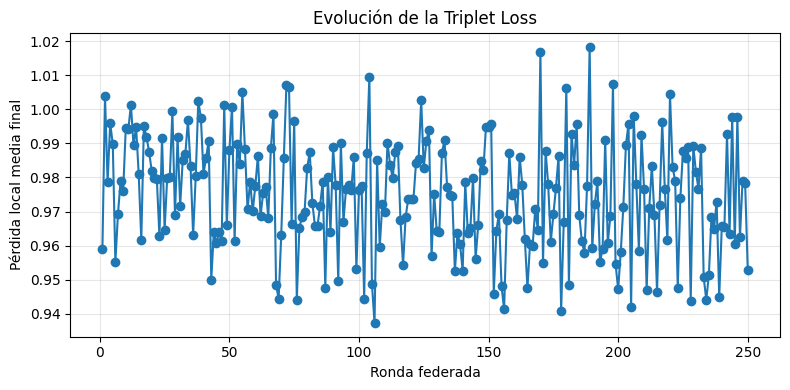

In [265]:
# ==========================================
# EVOLUCIÓN DE LA PÉRDIDA
# ==========================================

import matplotlib.pyplot as plt

history_df = pd.DataFrame(history)

plt.figure(figsize=(8, 4))
plt.plot(
    history_df["round"],
    history_df["mean_local_loss"],
    marker="o"
)

plt.xlabel("Ronda federada")
plt.ylabel("Pérdida local media final")
plt.title("Evolución de la Triplet Loss")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [266]:
DATOS

,ID,0,1,2,3,4,5,6,7,8,...,14,15,16,17,18,19,20,21,22,23
0,AA,98.587802,86.745731,56.358585,36.834396,197.608060,136.276753,52.395570,32.062011,65.348715,...,20.552723,13.481989,71.452360,104.233713,8.401132,4.834997,170.172671,159.762891,7.858873,5.182043
1,AA,88.966905,84.193557,51.564241,39.888123,187.393759,141.326698,47.304950,32.308756,53.909220,...,18.268532,12.619065,59.123453,100.058671,5.869432,3.970952,170.338179,159.495509,5.131338,3.393768
2,AA,91.252315,91.830931,47.130514,40.372304,194.325836,149.540178,51.444049,36.339900,55.269524,...,15.559509,13.159775,57.505157,101.307417,5.777942,4.010542,169.262009,159.190330,5.283858,3.440455
3,AA,96.639765,104.209909,47.630940,37.634061,196.893628,149.292290,53.426817,36.046112,60.193631,...,22.916943,18.148518,57.757103,101.112273,6.612139,4.460182,169.867327,160.142545,5.566534,4.599890
4,AA,89.947971,92.995640,50.414484,39.064229,189.015450,147.932514,40.398781,27.612294,54.657868,...,19.119533,16.849820,52.958874,100.838511,4.504610,3.778899,168.950984,158.805548,5.306167,4.453209
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,BM,127.912790,133.445481,32.079157,29.580096,244.672160,197.138349,39.356321,36.642136,72.875521,...,14.782879,11.798829,54.369928,105.910148,4.974497,3.157457,169.747196,160.030848,5.098076,3.670494
196,BM,91.121313,97.617626,39.558384,45.980208,248.347543,198.211170,33.273462,37.947830,47.864605,...,13.073263,11.943245,47.108853,101.258393,4.459814,3.683198,169.166111,160.276642,4.474408,3.031059
197,BM,108.326835,126.595794,42.891434,56.605741,245.723538,195.692955,36.048172,38.236481,62.859467,...,14.021622,14.823061,52.609131,104.856995,4.182094,3.105163,169.572612,160.074037,4.885745,3.838300
198,BM,110.225339,157.538529,34.356549,43.282325,253.135105,204.237058,32.879725,35.117646,60.523009,...,11.847105,12.434741,48.838241,103.939735,2.840550,1.947260,168.534404,159.911230,3.150537,2.233821


In [332]:
DATOS=DATOS.head(160)

In [349]:
import numpy as np
import pandas as pd
import copy

# ==========================================
# 1. HIPERPARÁMETROS Y CONFIGURACIÓN
# ==========================================
NUM_CLIENTS = 8
SAMPLES_PER_IDENTITY = 5
ROUNDS = 400
LOCAL_EPOCHS = 6
BATCH_SIZE = 16

# Ajustes  para convergencia
LEARNING_RATE = 0.05
ALPHA = 0.5            # Margen estándar para Triplet Loss
K = 16                 # Número de centros RBF
d = 8                  # Dimensión del embedding
RANDOM_SEED = 2026

# df = DATOS
id_col = df.columns[0]
feature_cols = list(df.columns[1:])
D = len(feature_cols)

X = df[feature_cols].to_numpy(dtype=np.float64)
identity_ids = df[id_col].to_numpy()

In [350]:
# ==========================================
# 2. PARTICIÓN FEDERADA
# ==========================================
def create_federated_clients(X, identity_ids, num_clients, seed=2026):
    rng = np.random.default_rng(seed)
    unique_ids = np.unique(identity_ids)

    shuffled_ids = rng.permutation(unique_ids)
    ids_by_client = np.array_split(shuffled_ids, num_clients)

    clients = []
    for client_ids in ids_by_client:
        mask = np.isin(identity_ids, client_ids)
        clients.append({
            "X": X[mask],
            "ids": identity_ids[mask],
            "unique_ids": client_ids
        })

    return clients

clients = create_federated_clients(X, identity_ids, NUM_CLIENTS, seed=RANDOM_SEED)

In [351]:
# ==========================================
# 3. CLASE DEL MODELO RBF Y TRIPLET LOSS
# ==========================================
class RBFMetricModel:
    def __init__(self, D, K, d, global_pool, seed=2026):
        rng = np.random.default_rng(seed)

        # CORRECCIÓN: 'mu' se inicializa tomando muestras aleatorias del pool global
        # Esto asegura que los centros representen todo el espacio desde la ronda 1.
        selected = rng.choice(len(global_pool), size=K, replace=False)
        self.mu = global_pool[selected].copy()

        self.W = rng.normal(loc=0.0, scale=1.0 / np.sqrt(K), size=(d, K))
        self.b = np.zeros(d, dtype=np.float64)

        # CORRECCIÓN: Gamma inicial mucho más bajo para evitar colapso (Phi = 0)
        self.gamma = np.full(K, 0.01 / D, dtype=np.float64)

    def forward(self, X):
        # Distancia al cuadrado: ||X - mu||^2 -> (B, K)
        diff = X[:, None, :] - self.mu[None, :, :]
        sq_dist = np.sum(diff**2, axis=2)

        # Activación RBF
        Phi = np.exp(-sq_dist * self.gamma[None, :])

        # Proyección lineal
        Z = Phi @ self.W.T + self.b
        return Z, Phi, diff, sq_dist

    def compute_gradients(self, A, P, N, alpha):
        B = len(A)

        Za, Phi_a, diff_a, r2_a = self.forward(A)
        Zp, Phi_p, diff_p, r2_p = self.forward(P)
        Zn, Phi_n, diff_n, r2_n = self.forward(N)

        # Distancias Triplet
        delta_ap, delta_an = Za - Zp, Za - Zn
        d_ap = np.sum(delta_ap**2, axis=1)
        d_an = np.sum(delta_an**2, axis=1)

        # Pérdida y activación de margen
        margins = d_ap - d_an + alpha
        active = (margins > 0).astype(np.float64)
        loss = np.mean(np.maximum(0.0, margins))

        if loss == 0:
            # Si no hay pérdida, los gradientes son cero
            return loss, {k: np.zeros_like(getattr(self, k)) for k in ['W', 'b', 'mu', 'gamma']}

        # Derivadas de la pérdida respecto a embeddings
        gZa = 2.0 * (Zn - Zp) * active[:, None] / B
        gZp = -2.0 * delta_ap * active[:, None] / B
        gZn = -2.0 * delta_an * active[:, None] / B

        # Gradientes de W y b
        grad_W = gZa.T @ Phi_a + gZp.T @ Phi_p + gZn.T @ Phi_n
        grad_b = np.sum(gZa + gZp + gZn, axis=0)

        # Derivadas intermedias (gPhi)
        gPhi_a = gZa @ self.W
        gPhi_p = gZp @ self.W
        gPhi_n = gZn @ self.W

        # Gradientes de mu
        grad_mu = (
            np.einsum("bk,bk,bkd->kd", gPhi_a, Phi_a, 2.0 * self.gamma[None, :, None] * diff_a) +
            np.einsum("bk,bk,bkd->kd", gPhi_p, Phi_p, 2.0 * self.gamma[None, :, None] * diff_p) +
            np.einsum("bk,bk,bkd->kd", gPhi_n, Phi_n, 2.0 * self.gamma[None, :, None] * diff_n)
        )

        # Gradientes de gamma
        grad_gamma = (
            np.sum(-gPhi_a * r2_a * Phi_a, axis=0) +
            np.sum(-gPhi_p * r2_p * Phi_p, axis=0) +
            np.sum(-gPhi_n * r2_n * Phi_n, axis=0)
        )

        return loss, {"W": grad_W, "b": grad_b, "mu": grad_mu, "gamma": grad_gamma}

    def apply_gradients(self, grads, lr):
        # 1. Gradient Clipping: Evita la explosión de gradientes
        # Limitamos los valores de los gradientes entre -1.0 y 1.0
        clip_value = 1.0
        for key in grads:
            grads[key] = np.clip(grads[key], -clip_value, clip_value)

        # 2. Actualización SGD
        self.W -= lr * grads["W"]
        self.b -= lr * grads["b"]
        self.mu -= lr * grads["mu"]
        self.gamma -= lr * grads["gamma"]

        # 3. RESTRICCIÓN CRÍTICA: gamma es la inversa de la varianza.
        # NUNCA puede ser negativo o cero. Lo limitamos a un mínimo de 1e-6.
        self.gamma = np.maximum(self.gamma, 1e-6)

In [352]:
# ==========================================
# 4. FUNCIONES DEL CLIENTE
# ==========================================
def build_triplets(X, ids, seed=None):
    rng = np.random.default_rng(seed)
    unique_ids = np.unique(ids)

    A, P, N = [], [], []
    for anchor_idx, anchor_id in enumerate(ids):
        # Positivo: misma id, distinto índice
        pos_candidates = np.where((ids == anchor_id) & (np.arange(len(ids)) != anchor_idx))[0]
        pos_idx = rng.choice(pos_candidates)

        # Negativo: distinta id
        neg_id = rng.choice(unique_ids[unique_ids != anchor_id])
        neg_idx = rng.choice(np.where(ids == neg_id)[0])

        A.append(X[anchor_idx])
        P.append(X[pos_idx])
        N.append(X[neg_idx])

    return np.array(A), np.array(P), np.array(N)

def train_client(global_model, client_data, epochs, batch_size, lr, alpha, seed):
    local_model = copy.deepcopy(global_model)
    rng = np.random.default_rng(seed)

    X_i, ids_i = client_data["X"], client_data["ids"]
    A, P, N = build_triplets(X_i, ids_i, seed=seed)
    num_samples = len(A)

    final_loss = 0.0
    for epoch in range(epochs):
        permutation = rng.permutation(num_samples)
        epoch_losses = []

        for start in range(0, num_samples, batch_size):
            idx = permutation[start:start + batch_size]
            loss, grads = local_model.compute_gradients(A[idx], P[idx], N[idx], alpha)
            local_model.apply_gradients(grads, lr)
            epoch_losses.append(loss)

        final_loss = np.mean(epoch_losses)

    return local_model, final_loss

In [353]:
# ==========================================
# 5. FEDERATED AVERAGING Y BUCLE PRINCIPAL
# ==========================================
def federated_averaging(local_models):
    global_model = copy.deepcopy(local_models[0])
    num_models = len(local_models)

    for param in ["W", "b", "mu", "gamma"]:
        stacked_params = np.stack([getattr(m, param) for m in local_models])
        setattr(global_model, param, np.mean(stacked_params, axis=0))

    return global_model

# 1. Crear Pool global representativo para inicialización (2 muestras por cliente)
global_pool = np.vstack([c["X"][:2] for c in clients])

# 2. Inicializar modelo global
global_model = RBFMetricModel(D=D, K=K, d=d, global_pool=global_pool, seed=RANDOM_SEED)

history_loss = []

print("Iniciando Entrenamiento Federado...\n")
for t in range(ROUNDS):
    local_models = []
    round_losses = []

    for i, client in enumerate(clients):
        local_model, loss = train_client(
            global_model=global_model,
            client_data=client,
            epochs=LOCAL_EPOCHS,
            batch_size=BATCH_SIZE,
            lr=LEARNING_RATE,
            alpha=ALPHA,
            seed=RANDOM_SEED + t * NUM_CLIENTS + i
        )
        local_models.append(local_model)
        round_losses.append(loss)
        mean_loss = np.mean(round_losses)
        history_loss.append(mean_loss)

    # Agregación de parámetros
    global_model = federated_averaging(local_models)

    mean_loss = np.mean(round_losses)
    if (t + 1) % 5 == 0 or t == 0:
        print(f"Ronda {t + 1:02d}/{ROUNDS} | Promedio Pérdida Local: {mean_loss:.4f}")

Iniciando Entrenamiento Federado...

Ronda 01/400 | Promedio Pérdida Local: 0.4815
Ronda 05/400 | Promedio Pérdida Local: 0.5040
Ronda 10/400 | Promedio Pérdida Local: 0.4980
Ronda 15/400 | Promedio Pérdida Local: 0.4788
Ronda 20/400 | Promedio Pérdida Local: 0.4939
Ronda 25/400 | Promedio Pérdida Local: 0.4888
Ronda 30/400 | Promedio Pérdida Local: 0.4986
Ronda 35/400 | Promedio Pérdida Local: 0.4999
Ronda 40/400 | Promedio Pérdida Local: 0.4939
Ronda 45/400 | Promedio Pérdida Local: 0.4854
Ronda 50/400 | Promedio Pérdida Local: 0.4964
Ronda 55/400 | Promedio Pérdida Local: 0.5001
Ronda 60/400 | Promedio Pérdida Local: 0.4930
Ronda 65/400 | Promedio Pérdida Local: 0.4954
Ronda 70/400 | Promedio Pérdida Local: 0.4818
Ronda 75/400 | Promedio Pérdida Local: 0.4963
Ronda 80/400 | Promedio Pérdida Local: 0.4975
Ronda 85/400 | Promedio Pérdida Local: 0.4918
Ronda 90/400 | Promedio Pérdida Local: 0.4990
Ronda 95/400 | Promedio Pérdida Local: 0.4957
Ronda 100/400 | Promedio Pérdida Local: 0.4

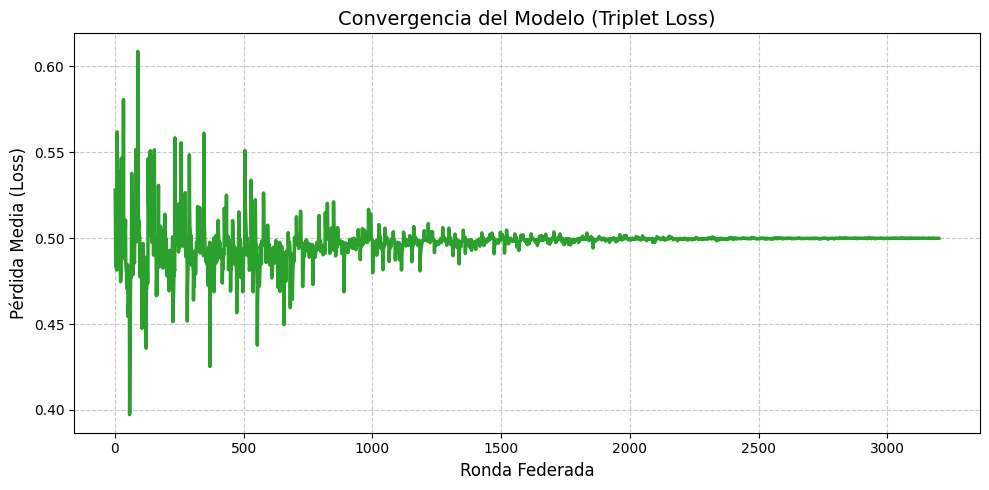

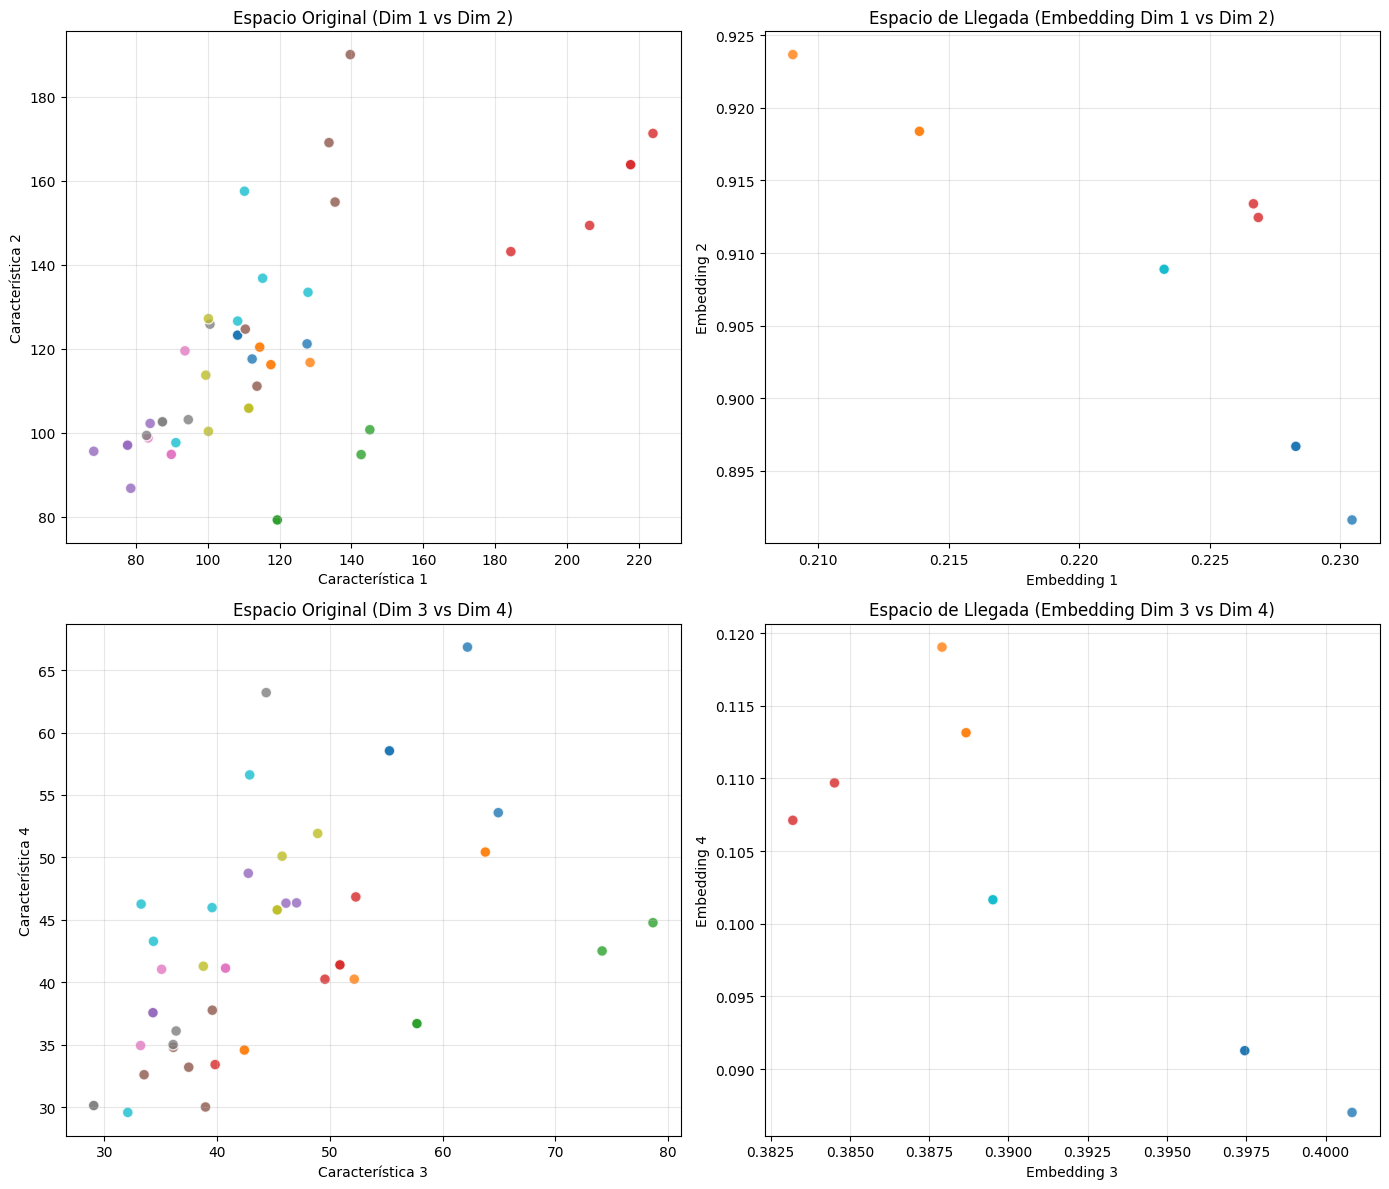

In [354]:
import matplotlib.pyplot as plt

# ==========================================
# GRÁFICA 1: EVOLUCIÓN DE LA PÉRDIDA
# ==========================================
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(history_loss) + 1), history_loss, marker='', color='#2ca02c', linewidth=2.5)
plt.title('Convergencia del Modelo (Triplet Loss)', fontsize=14)
plt.xlabel('Ronda Federada', fontsize=12)
plt.ylabel('Pérdida Media (Loss)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# ==========================================
# PREPARACIÓN PARA LAS GRÁFICAS DE ESPACIOS
# ==========================================
# 1. Seleccionar 10 identidades al azar para que los colores se distingan
rng_plot = np.random.default_rng(42)
unique_ids = np.unique(identity_ids)
selected_ids = rng_plot.choice(unique_ids, size=10, replace=False)

# Filtrar los datos originales
mask = np.isin(identity_ids, selected_ids)
X_plot = X[mask]
y_plot = identity_ids[mask]

# CONVERSIÓN CRÍTICA: Convertir textos ('AC', 'AD') a números (0, 1, 2...) para colorear
_, y_plot_numeric = np.unique(y_plot, return_inverse=True)

# 2. Obtener la transformación (embeddings) usando el modelo global final
Z_plot, _, _, _ = global_model.forward(X_plot)

# ==========================================
# GRÁFICA 2: COMPARACIÓN DE ESPACIOS
# ==========================================
fig, axs = plt.subplots(2, 2, figsize=(14, 12))
cmap = 'tab10' # Paleta de 10 colores distintos

# Fila 1: Dimensiones 1 y 2 (Nota que usamos c=y_plot_numeric)
axs[0, 0].scatter(X_plot[:, 0], X_plot[:, 1], c=y_plot_numeric, cmap=cmap, alpha=0.8, edgecolors='w', s=60)
axs[0, 0].set_title('Espacio Original (Dim 1 vs Dim 2)', fontsize=12)
axs[0, 0].set_xlabel('Característica 1')
axs[0, 0].set_ylabel('Característica 2')
axs[0, 0].grid(True, alpha=0.3)

axs[0, 1].scatter(Z_plot[:, 0], Z_plot[:, 1], c=y_plot_numeric, cmap=cmap, alpha=0.8, edgecolors='w', s=60)
axs[0, 1].set_title('Espacio de Llegada (Embedding Dim 1 vs Dim 2)', fontsize=12)
axs[0, 1].set_xlabel('Embedding 1')
axs[0, 1].set_ylabel('Embedding 2')
axs[0, 1].grid(True, alpha=0.3)

# Fila 2: Dimensiones 3 y 4
axs[1, 0].scatter(X_plot[:, 2], X_plot[:, 3], c=y_plot_numeric, cmap=cmap, alpha=0.8, edgecolors='w', s=60)
axs[1, 0].set_title('Espacio Original (Dim 3 vs Dim 4)', fontsize=12)
axs[1, 0].set_xlabel('Característica 3')
axs[1, 0].set_ylabel('Característica 4')
axs[1, 0].grid(True, alpha=0.3)

axs[1, 1].scatter(Z_plot[:, 2], Z_plot[:, 3], c=y_plot_numeric, cmap=cmap, alpha=0.8, edgecolors='w', s=60)
axs[1, 1].set_title('Espacio de Llegada (Embedding Dim 3 vs Dim 4)', fontsize=12)
axs[1, 1].set_xlabel('Embedding 3')
axs[1, 1].set_ylabel('Embedding 4')
axs[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Cantidad de puntos originales: 50
Cantidad de embeddings generados: 50


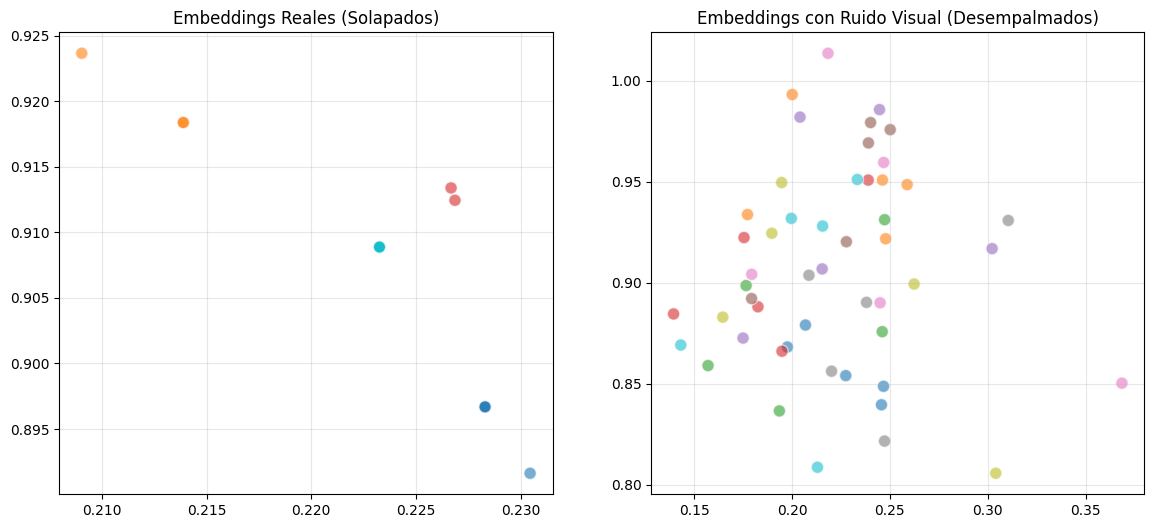

In [355]:
# 1. Comprobación matemática estricta
print(f"Cantidad de puntos originales: {X_plot.shape[0]}")
print(f"Cantidad de embeddings generados: {Z_plot.shape[0]}")

# 2. Agregar ruido visual (jitter) solo para la gráfica, para separar puntos solapados
jitter_strength = 0.05
rng_jitter = np.random.default_rng(42)

# Añadimos ruido a las primeras 4 dimensiones de Z
Z_plot_jitter = Z_plot + rng_jitter.normal(0, jitter_strength, Z_plot.shape)

# ==========================================
# GRÁFICA CON JITTER (Para ver los puntos ocultos)
# ==========================================
fig, axs = plt.subplots(1, 2, figsize=(14, 6))
cmap = 'tab10'

# Sin Jitter (Puntos apilados)
axs[0].scatter(Z_plot[:, 0], Z_plot[:, 1], c=y_plot_numeric, cmap=cmap, alpha=0.6, edgecolors='w', s=80)
axs[0].set_title('Embeddings Reales (Solapados)', fontsize=12)
axs[0].grid(True, alpha=0.3)

# Con Jitter (Puntos separados visualmente)
axs[1].scatter(Z_plot_jitter[:, 0], Z_plot_jitter[:, 1], c=y_plot_numeric, cmap=cmap, alpha=0.6, edgecolors='w', s=80)
axs[1].set_title('Embeddings con Ruido Visual (Desempalmados)', fontsize=12)
axs[1].grid(True, alpha=0.3)

plt.show()

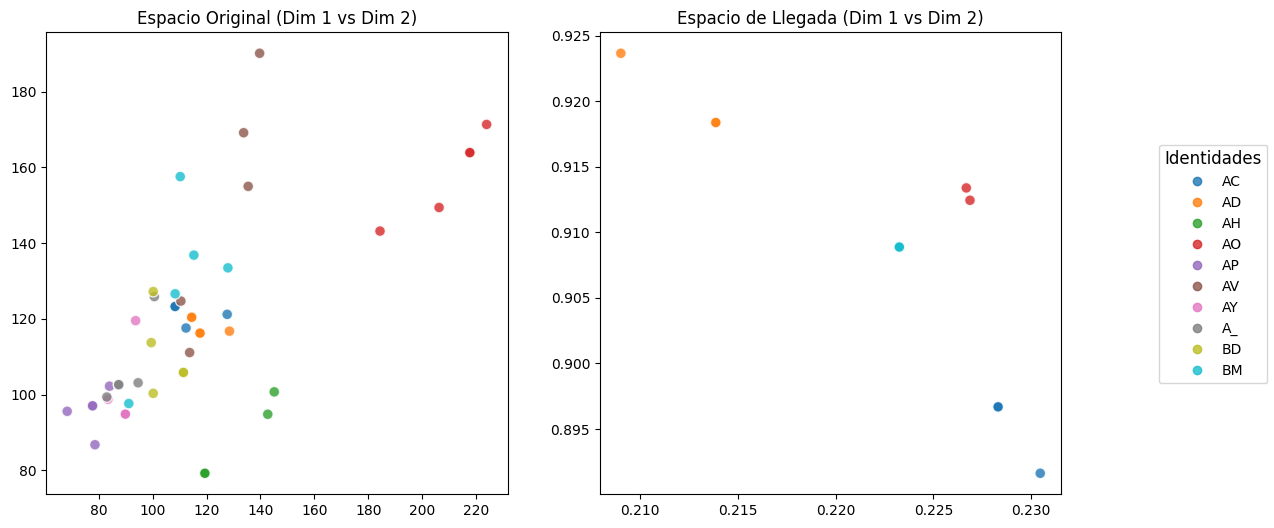

In [356]:
# 1. Obtenemos tanto las etiquetas de texto únicas como sus números
unique_labels, y_plot_numeric = np.unique(y_plot, return_inverse=True)

fig, axs = plt.subplots(1, 2, figsize=(14, 6))
cmap = 'tab10' # Paleta de 10 colores

# Gráfica Original
scatter_orig = axs[0].scatter(X_plot[:, 0], X_plot[:, 1], c=y_plot_numeric, cmap=cmap, alpha=0.8, edgecolors='w', s=60)
axs[0].set_title('Espacio Original (Dim 1 vs Dim 2)')

# Gráfica de Llegada (Embeddings)
scatter_emb = axs[1].scatter(Z_plot[:, 0], Z_plot[:, 1], c=y_plot_numeric, cmap=cmap, alpha=0.8, edgecolors='w', s=60)
axs[1].set_title('Espacio de Llegada (Dim 1 vs Dim 2)')

# ==========================================
# CÓDIGO PARA AGREGAR LA LEYENDA
# ==========================================
# Extraemos los colores que usó la gráfica y les ponemos el texto de unique_labels ('AC', 'AD'...)
handles, _ = scatter_emb.legend_elements()
fig.legend(handles, unique_labels, loc='center right', title='Identidades', fontsize=10, title_fontsize=12)

# Ajustar márgenes para hacer espacio a la leyenda
plt.subplots_adjust(right=0.85)
plt.show()

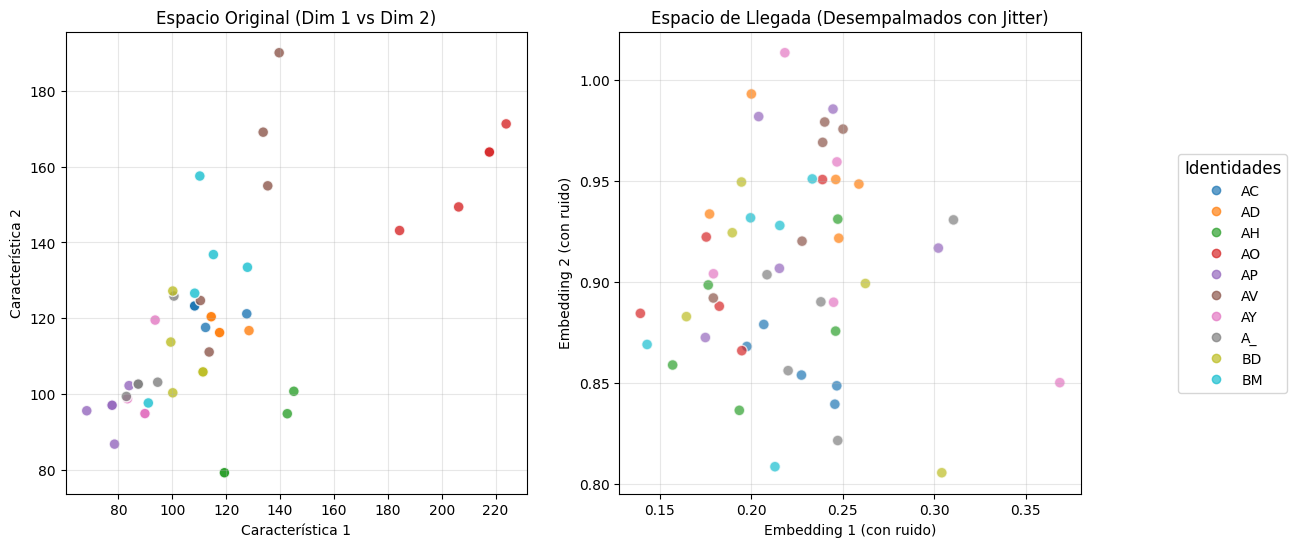

In [357]:
# 1. Obtenemos tanto las etiquetas de texto únicas como sus números
unique_labels, y_plot_numeric = np.unique(y_plot, return_inverse=True)

# 2. Aplicamos el ruido visual (jitter) a los embeddings para separarlos
jitter_strength = 0.05
rng_jitter = np.random.default_rng(42)
Z_plot_jitter = Z_plot + rng_jitter.normal(0, jitter_strength, Z_plot.shape)

# 3. Preparamos las gráficas
fig, axs = plt.subplots(1, 2, figsize=(14, 6))
cmap = 'tab10' # Paleta de 10 colores distintos

# Gráfica 1: Espacio Original
scatter_orig = axs[0].scatter(X_plot[:, 0], X_plot[:, 1],
                              c=y_plot_numeric, cmap=cmap,
                              alpha=0.8, edgecolors='w', s=60)
axs[0].set_title('Espacio Original (Dim 1 vs Dim 2)', fontsize=12)
axs[0].set_xlabel('Característica 1')
axs[0].set_ylabel('Característica 2')
axs[0].grid(True, alpha=0.3)

# Gráfica 2: Espacio de Llegada con Jitter (Desempalmados)
scatter_emb = axs[1].scatter(Z_plot_jitter[:, 0], Z_plot_jitter[:, 1],
                             c=y_plot_numeric, cmap=cmap,
                             alpha=0.7, edgecolors='w', s=60)
axs[1].set_title('Espacio de Llegada (Desempalmados con Jitter)', fontsize=12)
axs[1].set_xlabel('Embedding 1 (con ruido)')
axs[1].set_ylabel('Embedding 2 (con ruido)')
axs[1].grid(True, alpha=0.3)

# ==========================================
# CÓDIGO PARA AGREGAR LA LEYENDA
# ==========================================
# Extraemos los colores y les ponemos el texto real ('AC', 'AD'...)
handles, _ = scatter_emb.legend_elements()
fig.legend(handles, unique_labels, loc='center right', title='Identidades', fontsize=10, title_fontsize=12)

# Ajustar márgenes para que la leyenda no se superponga con la gráfica
plt.subplots_adjust(right=0.85)
plt.show()